# RoadScan | رحلة تطوير كاشف تلف الطرق
## من أول تدريب YOLO إلى اعتماد Run17 المعدل
نطاق ريماس: كاشف YOLO وتجارب التدريب والتقييم والتكامل. توثيق 1 نوفمبر 2026.
شرح قبل الكود وتفسير بعده مع الأرقام والمدد والنجاحات والمحاولات غير الناجحة. هذه نوتبوك تحليل للمخرجات المحفوظة؛ تعمل دون GPU أو أوزان أو اتصال، ولا تعيد تدريب أو استدلال أي موديل.
**المعتمد Run17 fine-tuned** عند confidence=0.46 ودقة640. الأوزان المنشورة كانت نقطة بداية مع نسبتها لأصحابها؛ تعديلها لا يعني بناء المعمارية من الصفر.
المحلي:190 صورة و333 مربع ضرر و56 صورة سليمة، وسم مساعد ثم مراجعة الفريق. سبق الاطلاع والتقييم عليها؛ النتائج تشخيصية وليست اختبارًا جديدًا مستقلًا. لا ننشر صورها هنا.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
DATA=json.loads('{"as_of": "2026-11-01", "adopted_run": 17, "checkpoint": "run17_best_finetuned.pt", "sha256": "25b412ff18c05e2607f4bc61b872f39826e8d53ffdc7647654c1f419e355d15f", "confidence": 0.46, "imgsz": 640, "nms_iou": 0.7, "max_det": 300, "local_independent": false, "v2": [{"run": "Run14", "AP50": 0.22709511612951033, "AP5095": 0.08732461846272412, "P_curve": 0.2978121059947873, "R_curve": 0.30414246734780614}, {"run": "Run15", "AP50": 0.9619632619436428, "AP5095": 0.6712533095450459, "P_curve": 0.9242092286525201, "R_curve": 0.9243685113882318}, {"run": "Run16", "AP50": 0.7937601819357739, "AP5095": 0.4467134595829971, "P_curve": 0.749665355972831, "R_curve": 0.6998771963393245}, {"run": "Run17", "AP50": 0.9593002182315967, "AP5095": 0.6578988230976404, "P_curve": 0.9173665652792682, "R_curve": 0.9255760963761883}], "e3": [{"arm": "all_on", "epochs": 7, "training_seconds": 925.2470244589999, "checkpoint_sha256": "f545a04623a660315783e4a5ff496e76356027f88c75c4410e4aeee1023877a6", "mAP50": 0.9585909477183958, "mAP50_95": 0.6530270407651321, "precision": 0.9180262600489292, "recall": 0.9206208516479517, "delta_vs_all_on_pp": 0.0}, {"arm": "no_mosaic", "epochs": 7, "training_seconds": 899.0262887979998, "checkpoint_sha256": "4b3fb51e50856cb4a3dea5eedb5b1dc85aca1b216e82886a9b80a927c500d19f", "mAP50": 0.9560690047266027, "mAP50_95": 0.6458525859173626, "precision": 0.9065134505372766, "recall": 0.9226773552587162, "delta_vs_all_on_pp": -0.7174454847769463}, {"arm": "no_hsv", "epochs": 7, "training_seconds": 900.013083673, "checkpoint_sha256": "6401ec80732f5bfe609cf2520c00b58b5f49aba9743a6cf1df14dab6515e9ed9", "mAP50": 0.9589209354760655, "mAP50_95": 0.6525107900062246, "precision": 0.9212396535371096, "recall": 0.9222594196839771, "delta_vs_all_on_pp": -0.05162507589074883}, {"arm": "no_horizontal_flip", "epochs": 7, "training_seconds": 903.4117692350001, "checkpoint_sha256": "be5899af428301b23d94ac7645e01372af1cc892a14247dc8af7b622bbb616db", "mAP50": 0.9569731515600903, "mAP50_95": 0.650502316899536, "precision": 0.9150082942862154, "recall": 0.9212465101895023, "delta_vs_all_on_pp": -0.25247238655961013}], "countries": [{"country": "China_MotorBike", "cohort_role": "development reused", "images": 1977, "mAP50": 0.9593002182315967, "mAP50_95": 0.6578988230976404, "box_macro_f1_supported_classes": 0.8955620683655904, "supported_classes": 4, "micro_precision": 0.892905866302865, "micro_recall": 0.844516129032258, "micro_f1": 0.8680371352785146, "TP": 3927, "FP": 471, "FN": 723, "false_positives_per_100_images": 23.823975720789075, "pothole_recall": 0.9659574468085106, "ground_truth_boxes": 4650, "evaluation_status": "Evaluable on supported classes only"}, {"country": "United_States", "cohort_role": "country held out from team fine-tuning", "images": 4804, "mAP50": 0.7643569651022853, "mAP50_95": 0.4972681613922478, "box_macro_f1_supported_classes": 0.6818467731489589, "supported_classes": 4, "micro_precision": 0.8206395960446035, "micro_recall": 0.7085376930063578, "micro_f1": 0.760479625658023, "TP": 7801, "FP": 1705, "FN": 3209, "false_positives_per_100_images": 35.49125728559534, "pothole_recall": 0.31851851851851853, "ground_truth_boxes": 11010, "evaluation_status": "Evaluable on supported classes only"}, {"country": "Japan", "cohort_role": "image held out; country represented in fine-tuning", "images": 500, "mAP50": 0.8227839445168597, "mAP50_95": 0.5052830724738768, "box_macro_f1_supported_classes": 0.7116882951003933, "supported_classes": 2, "micro_precision": 0.8415300546448088, "micro_recall": 0.6430062630480167, "micro_f1": 0.7289940828402367, "TP": 308, "FP": 58, "FN": 171, "false_positives_per_100_images": 11.6, "pothole_recall": null, "ground_truth_boxes": 479, "evaluation_status": "Evaluable on supported classes only"}, {"country": "India", "cohort_role": "image held out; country represented in fine-tuning", "images": 500, "mAP50": 0.6202704788588458, "mAP50_95": 0.402821799551391, "box_macro_f1_supported_classes": 0.5881578947368421, "supported_classes": 2, "micro_precision": 0.575, "micro_recall": 0.5476190476190477, "micro_f1": 0.5609756097560976, "TP": 23, "FP": 17, "FN": 19, "false_positives_per_100_images": 3.4, "pothole_recall": null, "ground_truth_boxes": 42, "evaluation_status": "Evaluable on supported classes only"}, {"country": "Czech", "cohort_role": "annotation-empty diagnostic cohort from a represented country", "images": 500, "mAP50": null, "mAP50_95": null, "box_macro_f1_supported_classes": null, "supported_classes": 0, "micro_precision": 0.0, "micro_recall": null, "micro_f1": null, "TP": 0, "FP": 26, "FN": 0, "false_positives_per_100_images": 5.2, "pothole_recall": null, "ground_truth_boxes": 0, "evaluation_status": "No labeled damage boxes: AP/recall/F1 not evaluable"}], "perclass": [{"cls": "D00", "AP50": "0.940279", "AP50_95": "0.662192"}, {"cls": "D10", "AP50": "0.929384", "AP50_95": "0.603965"}, {"cls": "D20", "AP50": "0.981268", "AP50_95": "0.733816"}, {"cls": "D40", "AP50": "0.986269", "AP50_95": "0.631623"}], "thresholds": [{"confidence": 0.25, "macro_precision": 0.795483051262463, "macro_recall": 0.9457947359516504, "macro_f1": 0.8626608246552654, "micro_precision": 0.752972027972028, "micro_recall": 0.926236559139785, "micro_f1": 0.8306653809064609, "pothole_precision": 0.8769230769230769, "pothole_recall": 0.9702127659574468, "pothole_f1": 0.9212121212121213, "false_positives": 1413, "false_negatives": 343, "false_positives_per_100_images": 71.47192716236722, "per_class": [{"damage_code": "D00", "TP": 2437, "FP": 813, "FN": 241, "precision": 0.7498461538461538, "recall": 0.9100074682598954, "f1": 0.8221997300944669, "support": 2678}, {"damage_code": "D10", "TP": 1017, "FP": 479, "FN": 79, "precision": 0.6798128342245989, "recall": 0.9279197080291971, "f1": 0.7847222222222222, "support": 1096}, {"damage_code": "D20", "TP": 625, "FP": 89, "FN": 16, "precision": 0.8753501400560224, "recall": 0.9750390015600624, "f1": 0.922509225092251, "support": 641}, {"damage_code": "D40", "TP": 228, "FP": 32, "FN": 7, "precision": 0.8769230769230769, "recall": 0.9702127659574468, "f1": 0.9212121212121213, "support": 235}]}, {"confidence": 0.46, "macro_precision": 0.9059039172386201, "macro_recall": 0.8867372204613508, "macro_f1": 0.8955620683655904, "micro_precision": 0.892905866302865, "micro_recall": 0.844516129032258, "micro_f1": 0.8680371352785146, "pothole_precision": 0.941908713692946, "pothole_recall": 0.9659574468085106, "pothole_f1": 0.9537815126050421, "false_positives": 471, "false_negatives": 723, "false_positives_per_100_images": 23.823975720789075, "per_class": [{"damage_code": "D00", "TP": 2215, "FP": 270, "FN": 463, "precision": 0.8913480885311871, "recall": 0.827109783420463, "f1": 0.8580282781328685, "support": 2678}, {"damage_code": "D10", "TP": 869, "FP": 140, "FN": 227, "precision": 0.8612487611496531, "recall": 0.7928832116788321, "f1": 0.8256532066508313, "support": 1096}, {"damage_code": "D20", "TP": 616, "FP": 47, "FN": 25, "precision": 0.9291101055806938, "recall": 0.9609984399375975, "f1": 0.9447852760736196, "support": 641}, {"damage_code": "D40", "TP": 227, "FP": 14, "FN": 8, "precision": 0.941908713692946, "recall": 0.9659574468085106, "f1": 0.9537815126050421, "support": 235}]}], "local": [{"model": "Run17", "AP50": 0.2624511953497888, "AP5095": 0.13148693083466007, "P": 0.5, "R": 0.17417417417417416, "F1": 0.2583518930957684, "TP": 58, "FP": 58, "FN": 275}, {"model": "Run14", "AP50": 0.32096510562564323, "AP5095": 0.13217164929068886, "P": 0.6119402985074627, "R": 0.12312312312312312, "F1": 0.205, "TP": 41, "FP": 26, "FN": 292}, {"model": "Run23", "AP50": 0.24283155595723516, "AP5095": 0.12250076945092925, "P": 0.7111111111111111, "R": 0.0960960960960961, "F1": 0.16931216931216933, "TP": 32, "FP": 13, "FN": 301}], "journey": [{"run": 3, "work": "YOLOv8n / 600-image pilot", "status": "Executed", "interpretation": "China AP50 .0617 / AP5095 .0213; 30 epochs"}, {"run": 4, "work": "Nano/Small and no-Mosaic pilot", "status": "Partial / OOM", "interpretation": "Old split; 3 arms before CUDA OOM; not the final E2 grid"}, {"run": 5, "work": "YOLO v2 / evaluation recovery", "status": "Executed + quick saves", "interpretation": "Multiple saved versions are not independent trainings"}, {"run": 6, "work": "YOLO26s 768 and 960 continuation", "status": "Executed", "interpretation": "Old eligible data/splits; architecture and data changed"}, {"run": 7, "work": "Resolution audit preparation", "status": "Cancelled + Quick save", "interpretation": "No successful new training claimed"}, {"run": 8, "work": "Resolution evaluation", "status": "Executed; Quick export", "interpretation": "640/768/960 on saved checkpoints"}, {"run": 9, "work": "Data diagnosis", "status": "Executed; Quick export", "interpretation": "Backgrounds, class counts, country shift; no training"}, {"run": 10, "work": "Freezing pilot", "status": "Executed; Quick export", "interpretation": "Head/last3/all layers; 4-epoch short study"}, {"run": 11, "work": "Sampling / fixed crop", "status": "Executed; Quick export", "interpretation": "Random/balanced/unchanged and exploratory crop"}, {"run": 12, "work": "Rescoring / matching audit", "status": "Diagnostic", "interpretation": "Merged/pooled/relaxed-IoU criteria are not official AP gains"}, {"run": 13, "work": "Regularized recipe", "status": "Executed; Quick export", "interpretation": "Worse validation; not adopted"}, {"run": 14, "work": "Team-v2 YOLO11s", "status": "Executed", "interpretation": "8999 train; 1977 China development; 64 epochs, best49"}, {"run": 15, "work": "Published RDD YOLOv8s", "status": "Executed after failed versions", "interpretation": "No team training; unknown external pretraining overlap"}, {"run": 16, "work": "RDD fine-tuning", "status": "Executed", "interpretation": "17 epochs; best2; conventional recipe regressed"}, {"run": 17, "work": "Gentle fine-tuning", "status": "ADOPTED", "interpretation": "7 epochs; best2; team contribution, not better than published original"}, {"run": 18, "work": "D-code inference helper", "status": "Executed twice", "interpretation": "15 RDD smoke images; original then fine-tuned17; not local accuracy"}, {"run": 19, "work": "Confidence freeze", "status": "Executed", "interpretation": "0.46 selected on China development, not local"}, {"run": 20, "work": "E3 augmentation", "status": "Executed", "interpretation": "4 arms ×7 epochs, one seed, final-epoch primary metric"}, {"run": 21, "work": "Country / error audit", "status": "Executed + reviewed", "interpretation": "8281 images; limited support and upstream-overlap caveats"}, {"run": 22, "work": "Run14/17 local evaluation", "status": "Executed", "interpretation": "190 images,333 boxes,56 healthy; inspected/reused cohort"}, {"run": 23, "work": "Native attention/model comparison", "status": "Executed", "interpretation": "COCO11s vs v8s;1.5h each;45 vs47 epochs, not isolated attention"}, {"run": 24, "work": "Run17 960 fine-tune", "status": "Executed", "interpretation": "10 epochs; new960 did not beat reference17@640"}, {"run": 25, "work": "YOLO11m 960", "status": "Executed", "interpretation": "39 epochs; about6h training; old internal run24 names"}, {"run": 26, "work": "Run17 USA tiling", "status": "Failed before scoring", "interpretation": "Missing RDD input / StopIteration; no tiling result"}, {"run": 27, "work": "Run23 local evaluation", "status": "Executed", "interpretation": "Predeclared .001/.46; no local training/tuning; no replacement"}], "times": [{"run": 3, "event": "pilot", "seconds": 812, "time_basis": "Kaggle Save & Run All"}, {"run": 4, "event": "controlled pilot", "seconds": 12300, "time_basis": "rounded Kaggle elapsed; failed/OOM"}, {"run": 5, "event": "evaluation recovery", "seconds": 720, "time_basis": "rounded; no retraining"}, {"run": 5, "event": "v1 YOLO v2", "seconds": 5520, "time_basis": "rounded Kaggle elapsed"}, {"run": 5, "event": "v4 YOLO v2", "seconds": 11520, "time_basis": "rounded Kaggle elapsed"}, {"run": 6, "event": "quality/resolution", "seconds": 26340, "time_basis": "rounded Kaggle elapsed"}, {"run": 7, "event": "diagnosis/evaluation", "seconds": null, "time_basis": "unknown: Quick export does not measure execution"}, {"run": 8, "event": "diagnosis/evaluation", "seconds": null, "time_basis": "unknown: Quick export does not measure execution"}, {"run": 9, "event": "diagnosis/evaluation", "seconds": null, "time_basis": "unknown: Quick export does not measure execution"}, {"run": 10, "event": "diagnosis/evaluation", "seconds": null, "time_basis": "unknown: Quick export does not measure execution"}, {"run": 11, "event": "diagnosis/evaluation", "seconds": null, "time_basis": "unknown: Quick export does not measure execution"}, {"run": 12, "event": "diagnosis/evaluation", "seconds": null, "time_basis": "unknown: Quick export does not measure execution"}, {"run": 13, "event": "diagnosis/evaluation", "seconds": null, "time_basis": "unknown: Quick export does not measure execution"}, {"run": 14, "event": "team-v2", "seconds": 8400, "time_basis": "rounded Kaggle elapsed"}, {"run": 15, "event": "published eval v4", "seconds": 126, "time_basis": "successful version only"}, {"run": 16, "event": "fine-tuning", "seconds": 2356, "time_basis": "Kaggle elapsed"}, {"run": 17, "event": "gentle fine-tuning", "seconds": 1063.1, "time_basis": "Kaggle elapsed"}, {"run": 18, "event": "smoke v1", "seconds": 57.8, "time_basis": "no training"}, {"run": 18, "event": "smoke v2", "seconds": 57.1, "time_basis": "no training"}, {"run": 19, "event": "diagnosis/evaluation", "seconds": null, "time_basis": "unknown: Quick export does not measure execution"}, {"run": 20, "event": "E3 four arms", "seconds": 4047, "time_basis": "notebook elapsed incl evaluation"}, {"run": 21, "event": "countries", "seconds": 503, "time_basis": "no training"}, {"run": 22, "event": "local evaluation", "seconds": null, "time_basis": "unknown:11s Quick save is not execution time"}, {"run": 23, "event": "two-model comparison", "seconds": 11784.6, "time_basis": "notebook elapsed"}, {"run": 24, "event": "960 continuation", "seconds": 4087.5, "time_basis": "notebook elapsed"}, {"run": 25, "event": "YOLO11m960", "seconds": 23739.5, "time_basis": "notebook elapsed"}, {"run": 26, "event": "input error", "seconds": 138.6, "time_basis": "failed before scoring"}, {"run": 27, "event": "local23", "seconds": 211, "time_basis": "no training"}], "new23": [{"model": "new11s", "AP50": 0.227326, "AP5095": 0.0885386, "epochs": 45, "training_seconds": 5479.239877518}, {"model": "newv8s", "AP50": 0.194063, "AP5095": 0.0706751, "epochs": 47, "training_seconds": 5438.461557528}], "resolution": [{"model": "Run17", "size": 640, "AP5095": 0.6578987935}, {"model": "Run17", "size": 960, "AP5095": 0.4695991445}, {"model": "Run14", "size": 640, "AP5095": 0.0873246095}, {"model": "Run14", "size": 960, "AP5095": 0.0403363089}, {"model": "Run24new", "size": 640, "AP5095": 0.6444970631}, {"model": "Run24new", "size": 960, "AP5095": 0.495590661}, {"model": "Run25new11m", "size": 640, "AP5095": 0.1014720366}, {"model": "Run25new11m", "size": 960, "AP5095": 0.0791073931}], "local27_thresholds": [{"confidence": 0.001, "P": 0.00876361913784936, "R": 0.4444444444444444, "F1": 0.01718831659020963, "TP": 148, "FP": 16740, "FN": 185, "healthy_alarms": 56, "healthy_false_boxes": 2015}, {"confidence": 0.46, "P": 0.7111111111111111, "R": 0.0960960960960961, "F1": 0.16931216931216933, "TP": 32, "FP": 13, "FN": 301, "healthy_alarms": 1, "healthy_false_boxes": 1}], "notes": ["Metrics in fractions; plots in percent", "China repeatedly reused for development", "Published RDD upstream overlap unknown", "190 local images AI-assisted/team-reviewed and inspected/reused; not a fresh holdout", "Quick save time is not training time", "No model execution or retraining in summary"]}')
plt.rcParams.update({'figure.figsize':(11,5),'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'axes.titleweight':'bold','axes.titlesize':15,'axes.facecolor':'#f6f8fb','axes.prop_cycle':plt.cycler(color=['#087f8c','#5165ad','#e5a33d','#c75866'])})
TEAL,BLUE,AMBER,RED='#087f8c','#5165ad','#e5a33d','#c75866'
def bars(ax,labels,values,title,ylabel='Percent',color=TEAL):
    values=np.asarray(values,dtype=float);b=ax.bar(labels,values,color=color,width=.6)
    ax.bar_label(b,fmt='%.2f',padding=4,fontsize=10);ax.set_title(title,loc='left',pad=15);ax.set_ylabel(ylabel);ax.set_ylim(0,max(values)*1.23);ax.grid(axis='y',alpha=.15);ax.set_axisbelow(True)
def heat(ax,frame,title):
    v=frame.values.astype(float);im=ax.imshow(v,cmap='YlGnBu',aspect='auto');ax.set_xticks(range(len(frame.columns)),frame.columns);ax.set_yticks(range(len(frame)),frame.index);ax.set_title(title,loc='left',pad=15)
    for (i,j),n in np.ndenumerate(v):ax.text(j,i,f'{n:.1f}',ha='center',va='center',color='white' if (n-v.min())/(v.max()-v.min()+1e-12)>.55 else '#123')
    plt.colorbar(im,ax=ax,shrink=.8)
print('Adopted:',DATA['checkpoint']);print('SHA256:',DATA['sha256'])
print('Python + numpy + pandas + matplotlib. All charts use saved aggregate outputs.')

Adopted: run17_best_finetuned.pt
SHA256: 25b412ff18c05e2607f4bc61b872f39826e8d53ffdc7647654c1f419e355d15f
Python + numpy + pandas + matplotlib. All charts use saved aggregate outputs.


## 1 | خريطة العمل كاملة
بدأنا بعينة 600 صورة، ثم تجارب التشخيص، ثم عينة الفريق v2 والتدريب والتعديل اللطيف والتكامل والتقييم. بعض التشغيلات تحليل أو تقييم فقط؛ رقم التشغيل لا يعني بالضرورة موديلًا جديدًا. الجدول يوثق 03 إلى 27، والفهرس يحتفظ بالنسخ والفشل والإلغاء.

run,work,status,interpretation
3,YOLOv8n / 600-image pilot,Executed,China AP50 .0617 / AP5095 .0213; 30 epochs
4,Nano/Small and no-Mosaic pilot,Partial / OOM,Old split; 3 arms before CUDA OOM; not the final E2 grid
5,YOLO v2 / evaluation recovery,Executed + quick saves,Multiple saved versions are not independent trainings
6,YOLO26s 768 and 960 continuation,Executed,Old eligible data/splits; architecture and data changed
7,Resolution audit preparation,Cancelled + Quick save,No successful new training claimed
8,Resolution evaluation,Executed; Quick export,640/768/960 on saved checkpoints
9,Data diagnosis,Executed; Quick export,"Backgrounds, class counts, country shift; no training"
10,Freezing pilot,Executed; Quick export,Head/last3/all layers; 4-epoch short study
11,Sampling / fixed crop,Executed; Quick export,Random/balanced/unchanged and exploratory crop
12,Rescoring / matching audit,Diagnostic,Merged/pooled/relaxed-IoU criteria are not official AP gains


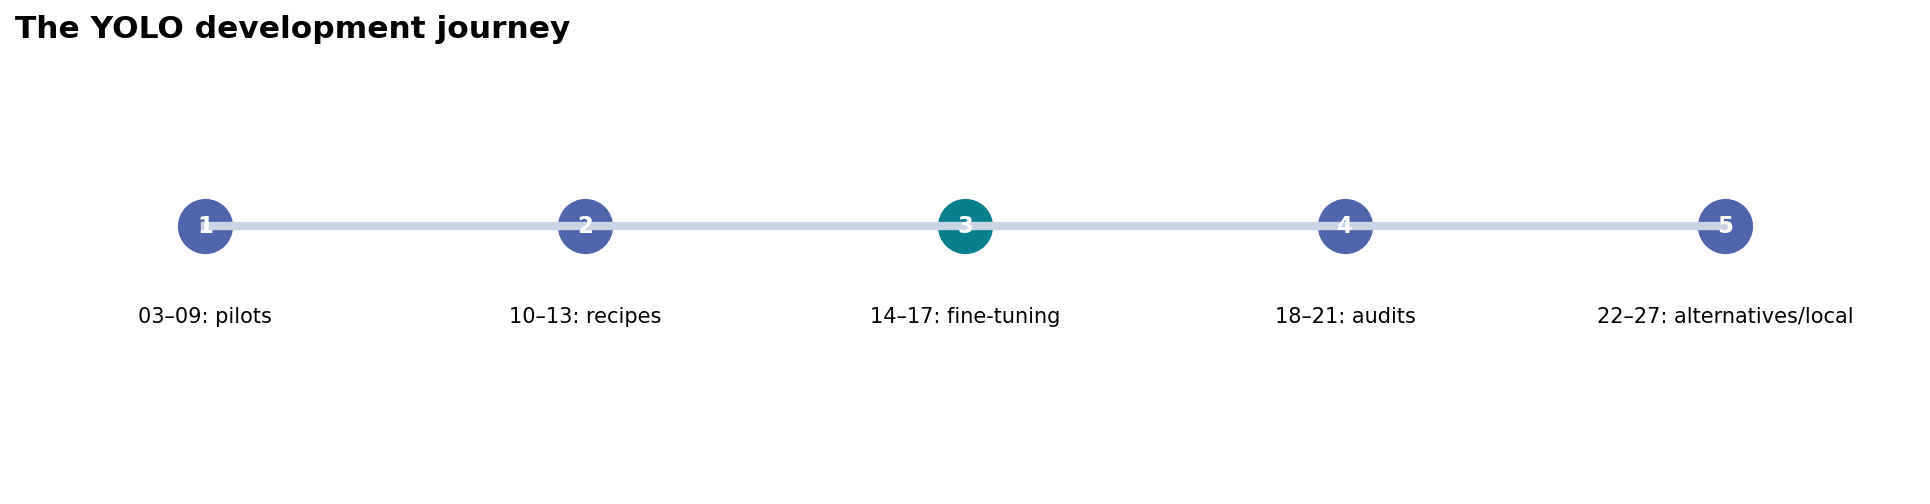

In [2]:
fig,ax=plt.subplots(figsize=(13,3.5))
labels=['03–09: pilots','10–13: recipes','14–17: fine-tuning','18–21: audits','22–27: alternatives/local']
ax.plot(range(5),[1]*5,lw=4,color='#cbd4e4')
for i,l in enumerate(labels):
    ax.scatter(i,1,s=650,color=TEAL if i==2 else BLUE);ax.text(i,1,str(i+1),ha='center',va='center',color='white',weight='bold');ax.text(i,.78,l,ha='center',fontsize=10)
ax.set(xlim=(-.5,4.5),ylim=(.4,1.4));ax.axis('off');ax.set_title('The YOLO development journey',loc='left');plt.tight_layout()
display(pd.DataFrame(DATA['journey']))

**القراءة:** العمل شمل بناء المسار وتحليل الأخطاء ورفض وصفات لم تنجح. فهرس الأرشيف يضم 30 نسخة، منها نسخة baseline خارج نطاق YOLO. لا نعد كل حفظ تدريبًا. تجربة fresh-experiment كانت تجهيز بروتوكول دون أوزان مدربة موثقة.

## 2 | البيانات والفئات
D00 شق طولي وD10 شق عرضي بالنسبة لاتجاه الطريق، وD20 تشقق شبكي وD40 حفرة. عينة البداية 600 صورة ثم 8,999 في v2. تحقق الصين 1,977 صورة و4,650 مربعًا، وأعيد استخدامه للتطوير. تغيير حجم العينة والتوزيع يغير بروتوكول المقارنة.

Country,Images,Healthy,Damaged
Japan,4000,500,3500
India,3500,500,3000
Czech,1499,427,1072


China GT boxes: D00=2678 D10=1096 D20=641 D40=235


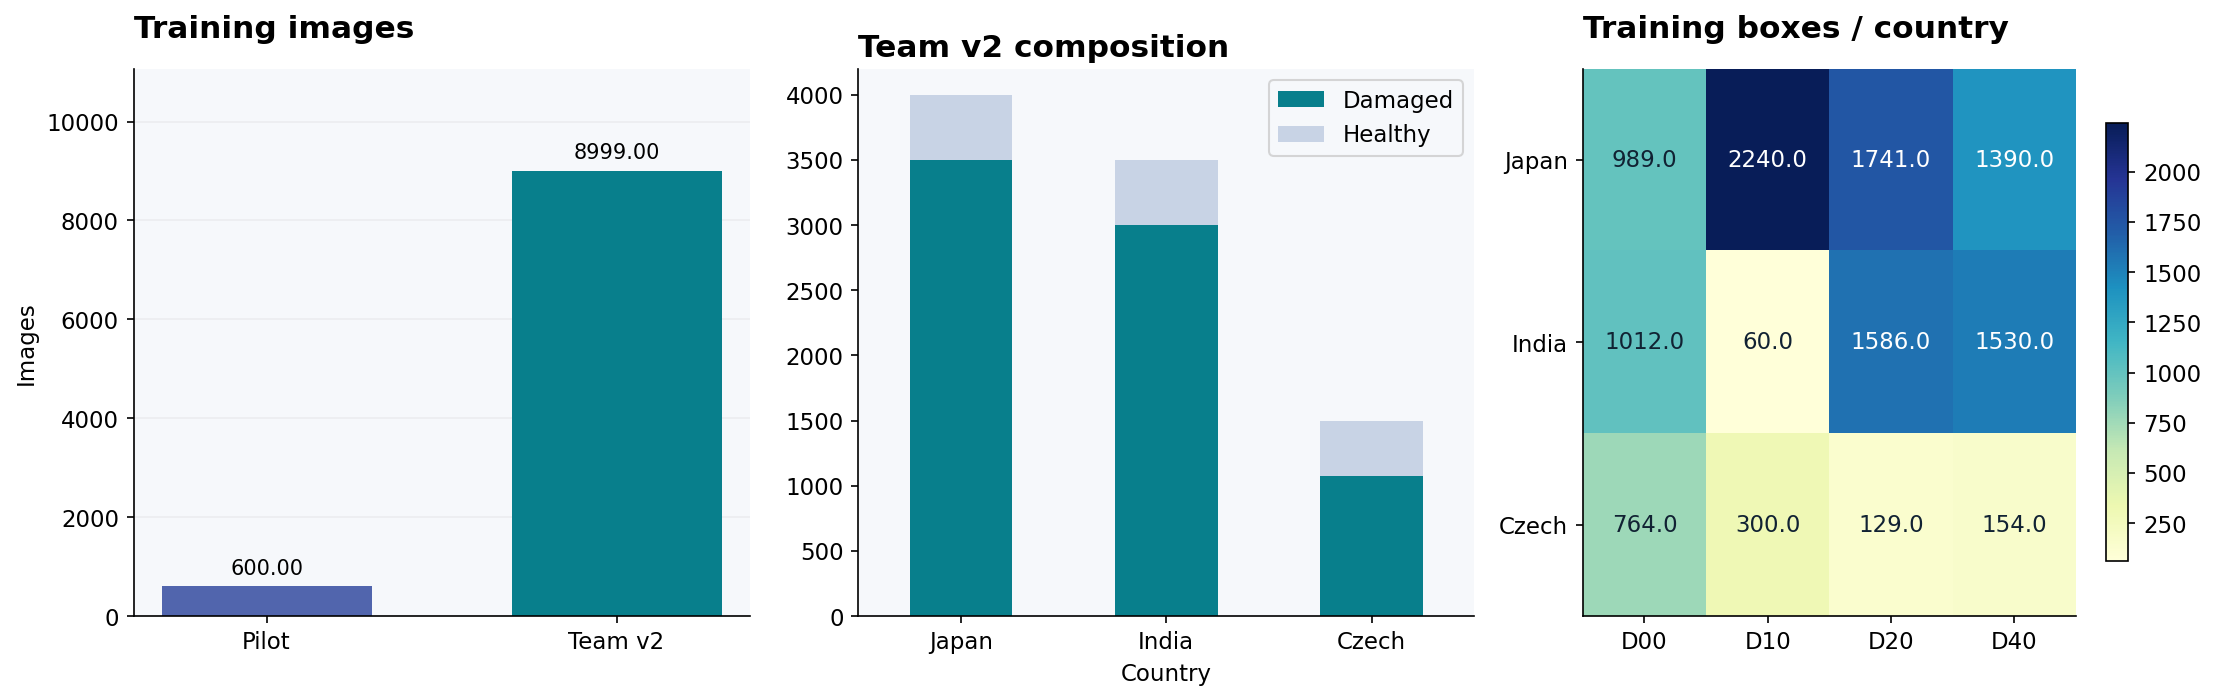

In [3]:
fig,axs=plt.subplots(1,3,figsize=(15,4.8))
bars(axs[0],['Pilot','Team v2'],[600,8999],'Training images','Images',[BLUE,TEAL])
co=pd.DataFrame({'Country':['Japan','India','Czech'],'Images':[4000,3500,1499],'Healthy':[500,500,427]});co['Damaged']=co.Images-co.Healthy
co.set_index('Country')[['Damaged','Healthy']].plot.bar(stacked=True,rot=0,ax=axs[1],color=[TEAL,'#c8d3e5']);axs[1].set_title('Team v2 composition',loc='left')
bx=pd.DataFrame([[989,2240,1741,1390],[1012,60,1586,1530],[764,300,129,154]],index=['Japan','India','Czech'],columns=['D00','D10','D20','D40']);heat(axs[2],bx,'Training boxes / country');plt.tight_layout();display(co)
print('China GT boxes: D00=2678 D10=1096 D20=641 D40=235')

**النتيجة:** عدم التوازن واضح؛ مثلًا D10 في الهند 60 مربعًا مقابل 2,240 في اليابان. احتفظنا بالدولة لفهم أثر المجال. توزيع الفئات وحده لا يثبت جودة التعميم.

## 3 | التجارب المبكرة: التجميد والموازنة والوصفة
03: YOLOv8n على 600 صورة، مع China AP50 نحو 6.17% وAP50–95 نحو 2.13%. التشغيل 04 نفذ أذرع Nano/Small/No-Mosaic قبل CUDA OOM. التشغيل 05 شمل تدريبًا واسترداد تقييم ونسخ CPU؛ و06 جرب YOLO26s.
07 تجهيز وإلغاء، و08 دقات مختلفة، و09 تشخيص، و10 تجميد، و11 موازنة وقص، و12 تدقيق مطابقة، و13 وصفة منتظمة. القيم في الرسوم التالية مقربة من الجداول التاريخية على البروتوكول القديم. نقارن داخل التجربة ولا ندمجها مع v2 في ترتيب يوحي بسبب واحد للتحسن.

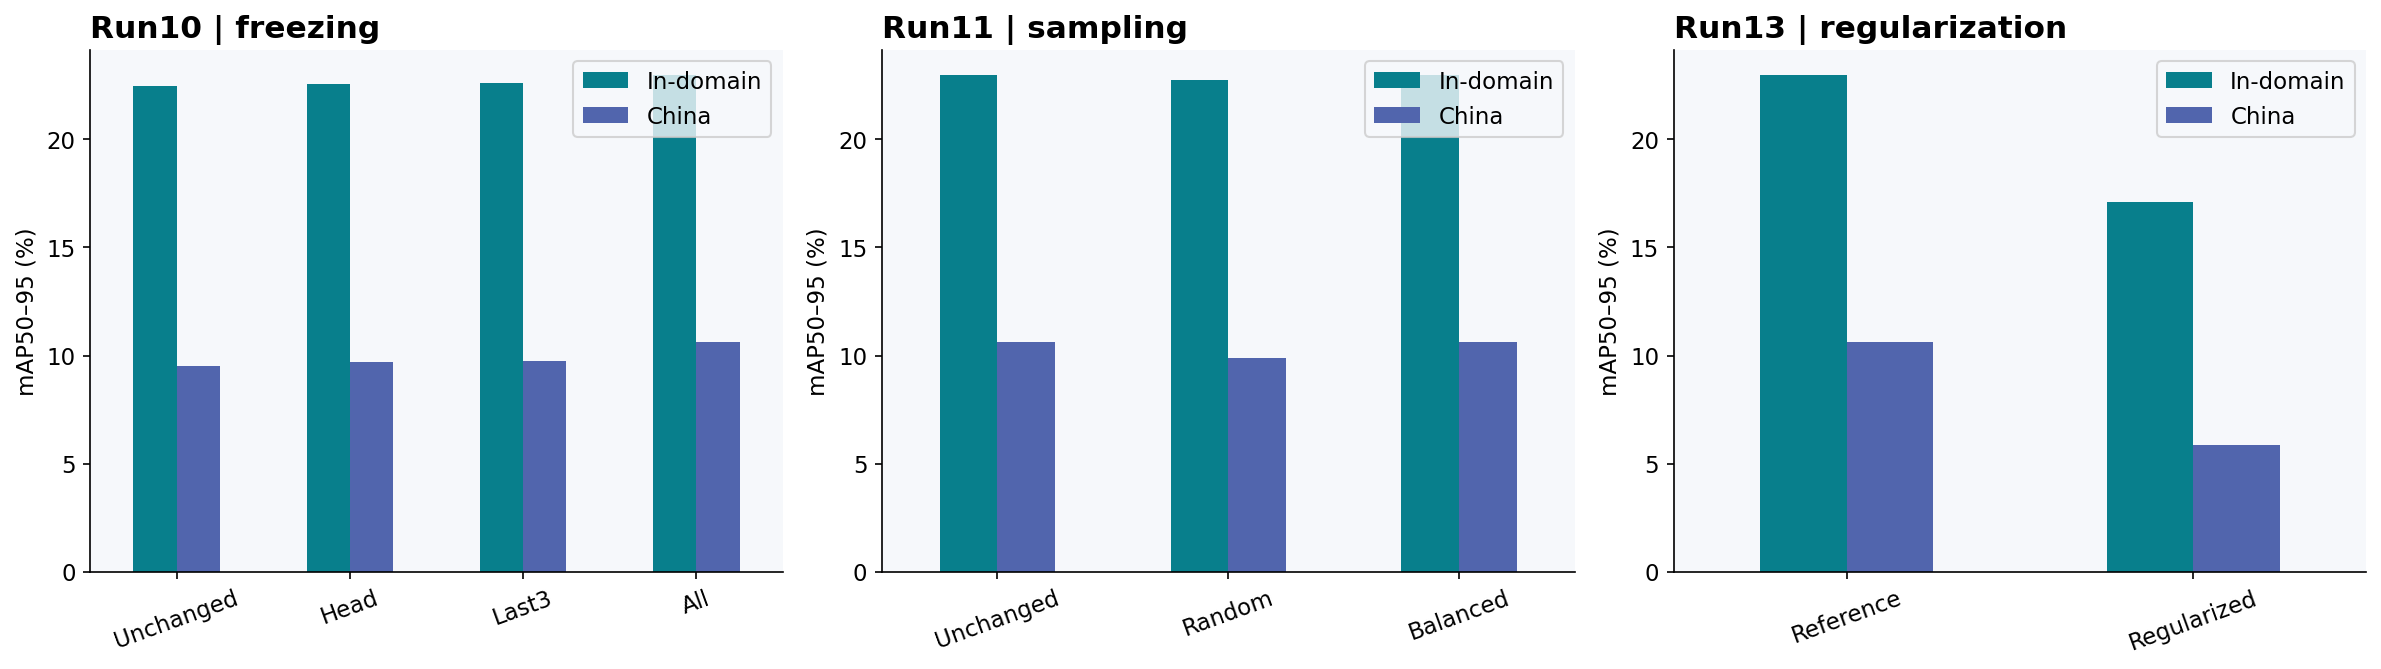

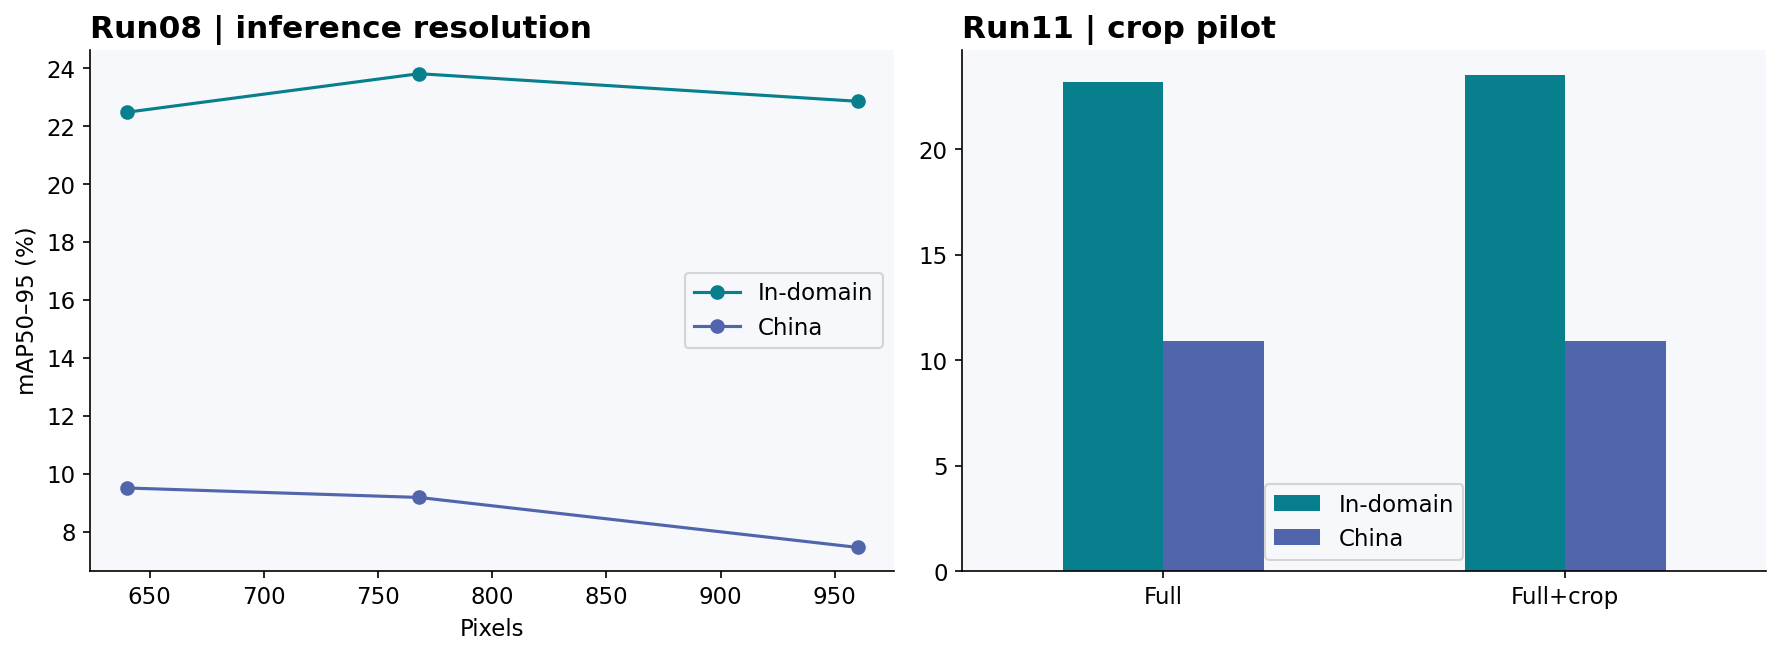

In [4]:
fig,axs=plt.subplots(1,3,figsize=(16,4.6))
sets=[('Run10 | freezing',['Unchanged','Head','Last3','All'],[.224765,.225455,.226032,.229925],[.0951034,.0968266,.0974065,.106458]),('Run11 | sampling',['Unchanged','Random','Balanced'],[.229925,.227579,.229618],[.106458,.099021,.106223]),('Run13 | regularization',['Reference','Regularized'],[.229925,.171135],[.106458,.058691])]
for ax,(title,ix,a,b) in zip(axs,sets):
    (pd.DataFrame({'In-domain':a,'China':b},index=ix)*100).plot.bar(ax=ax,rot=20);ax.set_title(title,loc='left');ax.set_ylabel('mAP50–95 (%)')
plt.tight_layout()
fig,axs=plt.subplots(1,2,figsize=(12,4.5))
for label,v in {'In-domain':[.224765,.238075,.228554],'China':[.095103,.091837,.074597]}.items():axs[0].plot([640,768,960],np.array(v)*100,marker='o',label=label)
axs[0].set_title('Run08 | inference resolution',loc='left');axs[0].set_xlabel('Pixels');axs[0].set_ylabel('mAP50–95 (%)');axs[0].legend()
(pd.DataFrame({'In-domain':[.231534,.235162],'China':[.108815,.109220]},index=['Full','Full+crop'])*100).plot.bar(ax=axs[1],rot=0);axs[1].set_title('Run11 | crop pilot',loc='left');plt.tight_layout()

**القرار:** التعديل الكامل أفضل قليلًا في تجربة قصيرة. الموازنة لم تتفوق على المرجع في معيار أسوأ دولة، والانتظام خفض الأداء. دقة 960 لم تكن أفضل تلقائيًا. مكسب القص محدود واستكشافي. التشغيل 12 غير IoU أو دمج المربعات والفئات للتشخيص؛ لا نسميه تحسن AP رسميًا.

## 4 | التشغيلات 14 إلى 17: لماذا اعتمدنا 17؟
14 بدأ YOLO11s من COCO وتدرب على v2. 15 قيم أوزان RDD منشورة، و16 عدلها بوصفة 14 الصريحة، و17 عدلها بلطف على العينة نفسها. اختلاف المعمارية ومصدر الأوزان يمنع وصف المقارنة بأنها تعزل YOLO11 مقابل v8.
**التداخل المحتمل مع تدريب المصدر المنشور غير محسوم**؛ لذلك ارتفاع تحقق RDD لا يثبت تعميمًا مستقلًا.

run,AP50,AP5095,P_curve,R_curve
Run14,0.22710,0.08732,0.29781,0.30414
Run15,0.96196,0.67125,0.92421,0.92437
Run16,0.79376,0.44671,0.74967,0.69988
Run17,0.95930,0.65790,0.91737,0.92558


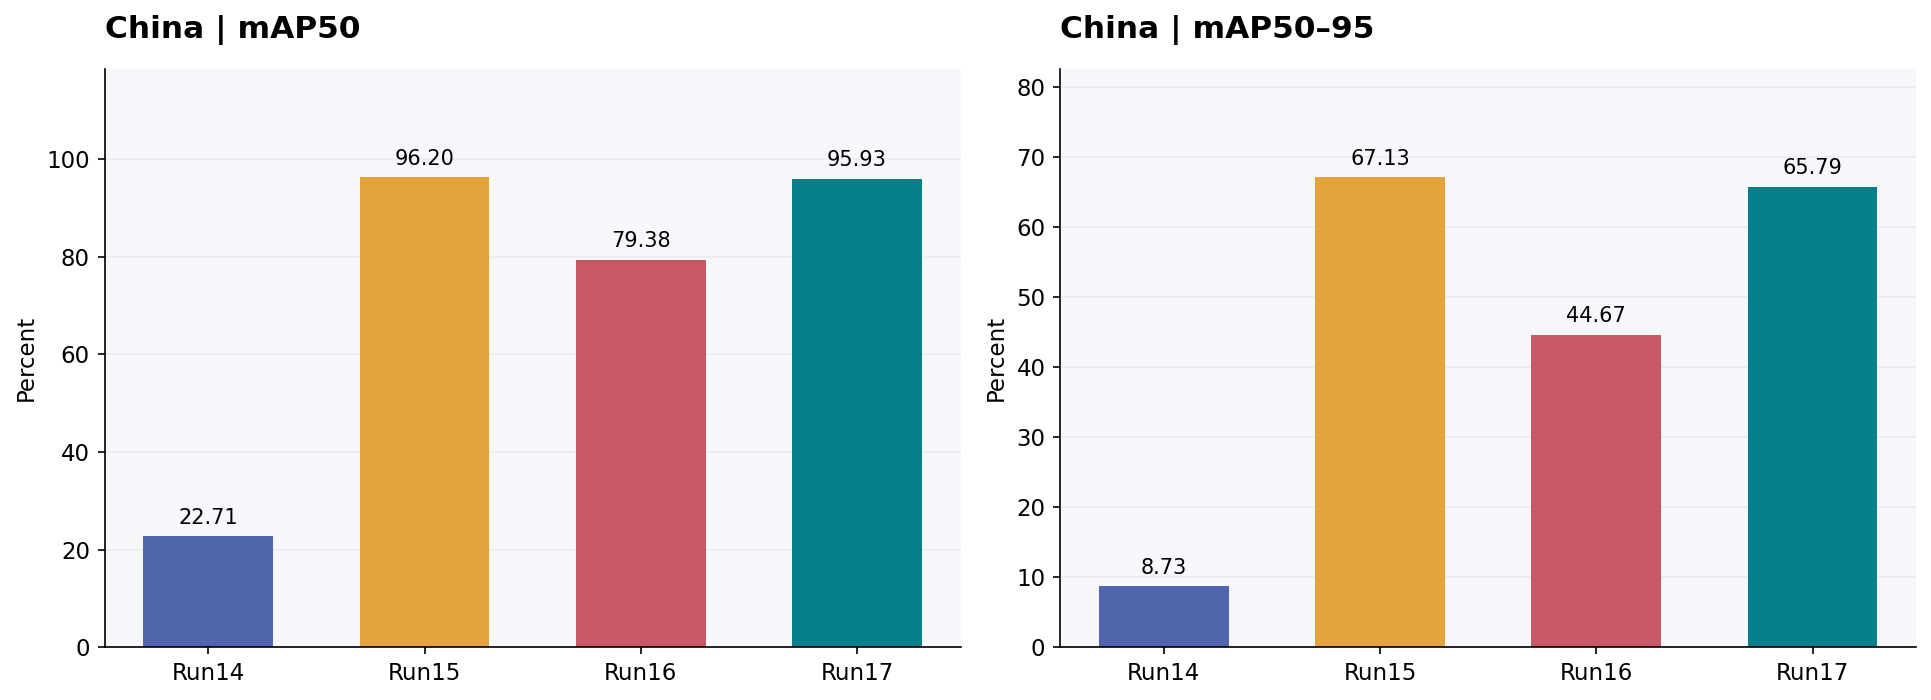

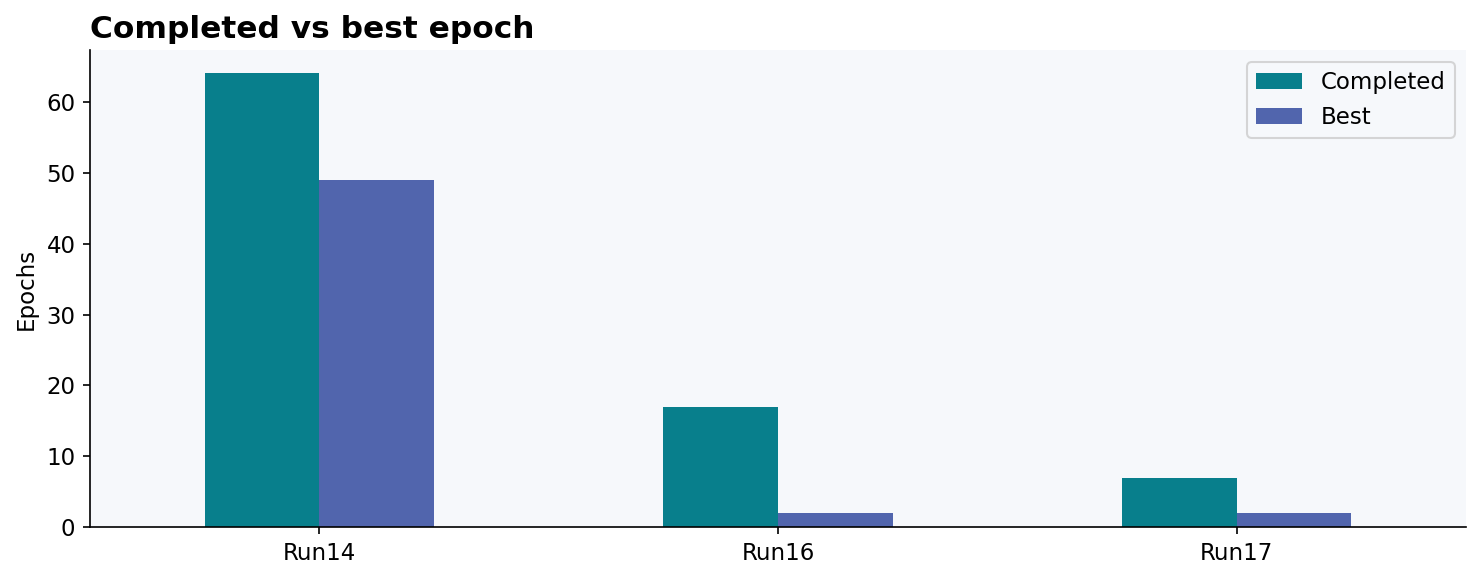

In [5]:
v=pd.DataFrame(DATA['v2']);display(v)
fig,axs=plt.subplots(1,2,figsize=(13,4.8))
for ax,key,title in [(axs[0],'AP50','China | mAP50'),(axs[1],'AP5095','China | mAP50–95')]:bars(ax,v.run,v[key]*100,title,color=[BLUE,AMBER,RED,TEAL])
plt.tight_layout()
fig,ax=plt.subplots(figsize=(10,4))
t=pd.DataFrame({'Completed':[64,17,7],'Best':[49,2,2]},index=['Run14','Run16','Run17']);t.plot.bar(ax=ax,rot=0);ax.set_title('Completed vs best epoch',loc='left');ax.set_ylabel('Epochs');plt.tight_layout()

**النتيجة:** 17 استعاد AP50–95 إلى 65.79% من 44.67% في 16، لكنه دون الأصل المنشور 67.13%. اعتماده قرار الفريق لأنه يتضمن fine-tuning فعليًا، وليس لأنه تفوق على الأصل. وصفته lr0=0.0001 وwarmup_bias_lr=0.0001 وpatience=5؛ اكتملت 7 epochs وأفضلها 2. يبقى الاختيار الآلي القديم للأصل في JSON سجلًا تاريخيًا، مع توثيق قرار الاعتماد اللاحق.

## 5 | الفئات والمقاييس والتكامل
AP عبر درجات الثقة مختلف عن Precision وRecall وF1 عند 0.46. كذلك Image Macro-F1 متعدد التسميات مختلف عن Box micro-F1. لا نخلط هذه الأرقام. التشغيل 18 أكد الدالة وأكواد D على 15 صورة RDD، أولًا بالأصل ثم 17 المعدل.

cls,AP50,AP50_95
D00,94.02790,66.21920
D10,92.93840,60.39650
D20,98.12680,73.38160
D40,98.62690,63.16230


Image macro-F1 at confidence .5: .9624306483 (different task from box F1)
Detector-only CPU median .190736s / p95 .194863s;20 images,2 threads,3 warmups.
Smoke test is integration evidence, not independent local accuracy or full app latency.


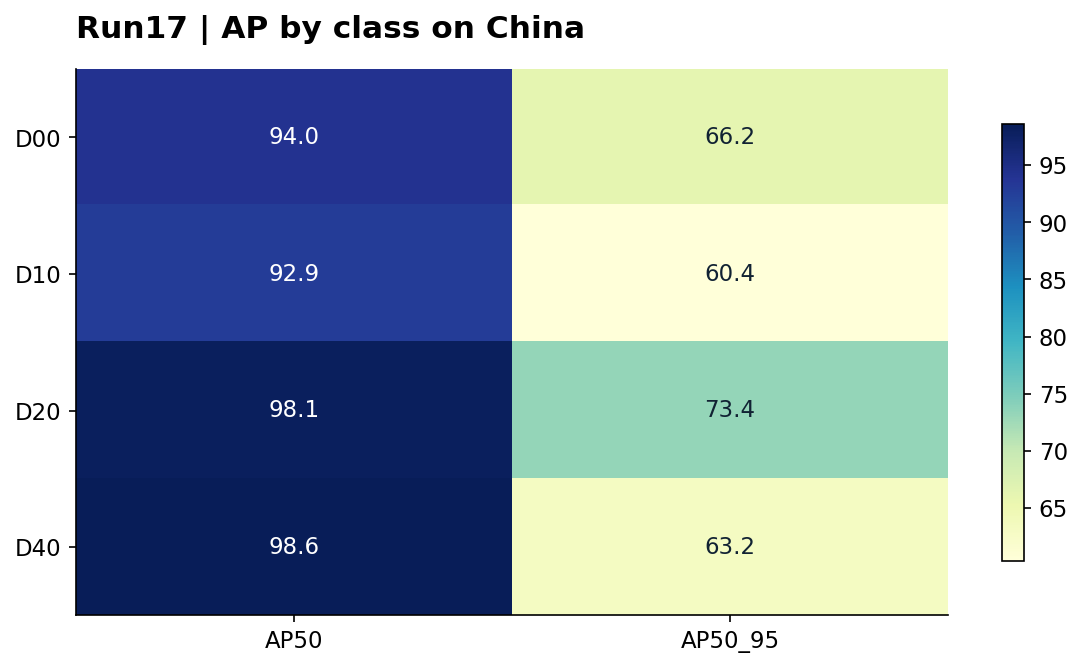

In [6]:
pc=pd.DataFrame(DATA['perclass']).set_index('cls').astype(float)*100
fig,ax=plt.subplots(figsize=(8,4.6));heat(ax,pc,'Run17 | AP by class on China');plt.tight_layout();display(pc.reset_index())
print('Image macro-F1 at confidence .5: .9624306483 (different task from box F1)')
print('Detector-only CPU median .190736s / p95 .194863s;20 images,2 threads,3 warmups.')
print('Smoke test is integration evidence, not independent local accuracy or full app latency.')

**التفسير:** الفئات قوية على تحقق الصين فقط. فحص CPU يخص الكاشف، وليس المسار الكامل مع الخصوصية والأولوية والتكرار. شغل التطبيق والزميلات له أدلته المنفصلة؛ لا نحكم عليه من تجربة الدالة.

## 6 | عتبة الثقة المثبتة في 19
اختيرت 0.46 على الصين قبل المحلي حسب Box Macro-F1 مع شرط استرجاع الحفر ≥90% إذا أمكن. نعرض نقطتين موثقتين فقط دون اختراع منحنى؛ منحنى F1 ومصفوفة الالتباس الأصلية في results/run17، ورسم اختيار العتبة في run19.

confidence,micro_precision,micro_recall,micro_f1,pothole_recall,false_positives,false_negatives
0.25000,0.75297,0.92624,0.83067,0.97021,1413,343
0.46000,0.89291,0.84452,0.86804,0.96596,471,723


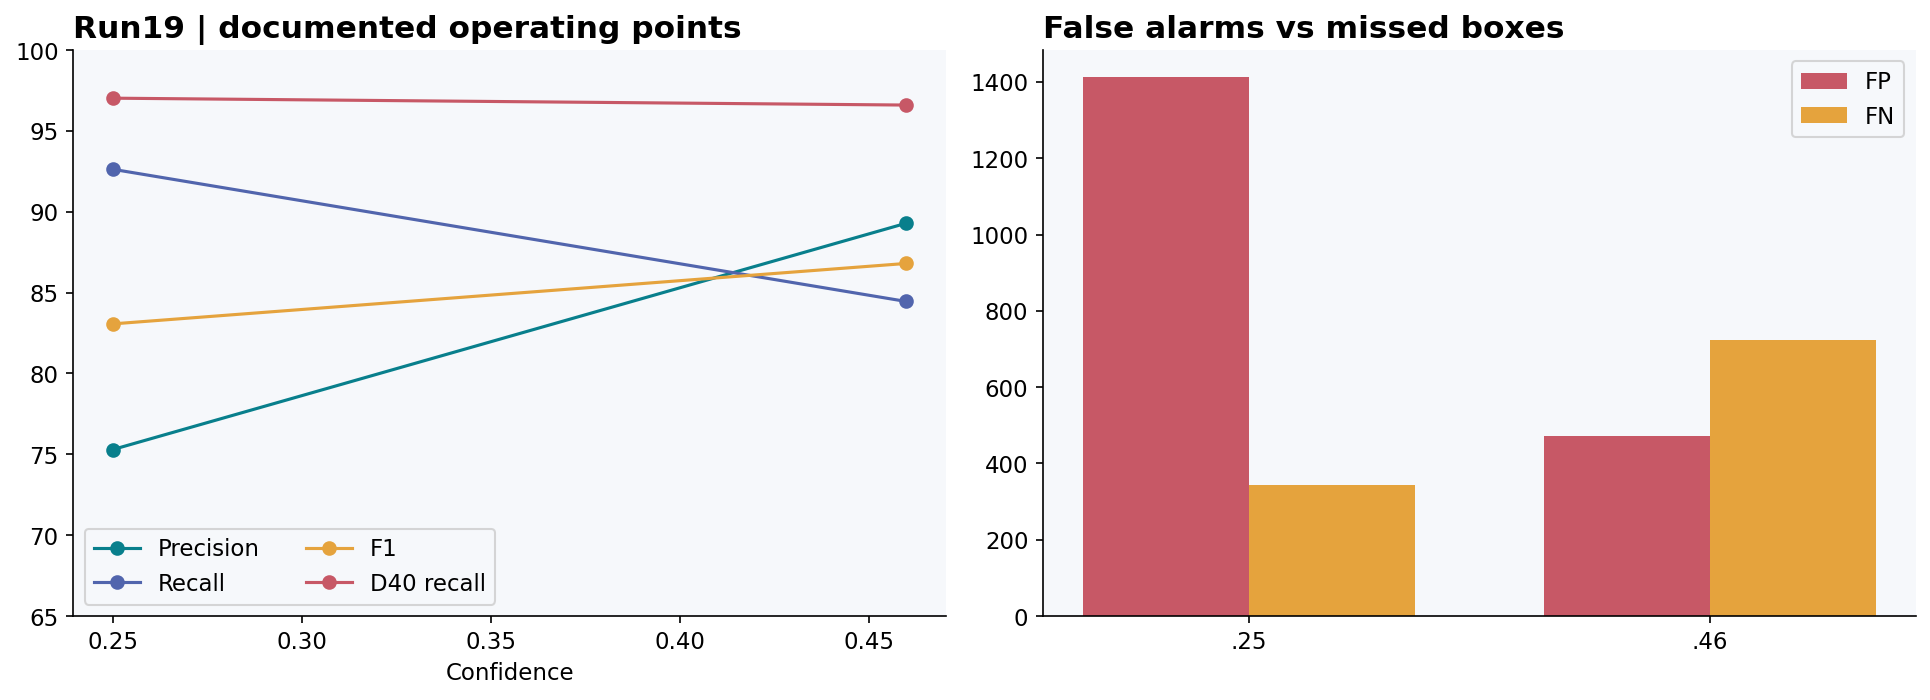

In [7]:
t=pd.DataFrame(DATA['thresholds']);fig,axs=plt.subplots(1,2,figsize=(13,4.8))
for k,l in [('micro_precision','Precision'),('micro_recall','Recall'),('micro_f1','F1'),('pothole_recall','D40 recall')]:axs[0].plot(t.confidence,t[k]*100,marker='o',label=l)
axs[0].set_title('Run19 | documented operating points',loc='left');axs[0].set_xlabel('Confidence');axs[0].set_ylim(65,100);axs[0].legend(ncol=2)
x=np.arange(2);axs[1].bar(x-.18,t.false_positives,.36,label='FP',color=RED);axs[1].bar(x+.18,t.false_negatives,.36,label='FN',color=AMBER);axs[1].set_xticks(x,['.25','.46']);axs[1].set_title('False alarms vs missed boxes',loc='left');axs[1].legend();plt.tight_layout();display(t[['confidence','micro_precision','micro_recall','micro_f1','pothole_recall','false_positives','false_negatives']])

**القرار:** عند 0.46 تحقق Precision=89.29% وRecall=84.45% وF1=86.80% واسترجاع الحفر 96.60% على الصين. تقليل FP من 1,413 إلى 471 صاحبته زيادة FN من 343 إلى 723. نبقي العتبة ثابتة ولا نعدلها لاستخراج نتيجة محلية أجمل. NMS IoU=0.7 مختلف عن IoU المطابقة 0.5.

## 7 | E3: تقنيات تحسين البيانات
20 نفذ all-on ثم إزالة Mosaic ثم HSV ثم Horizontal Flip. سبع epochs لكل ذراع، نقطة بداية واحدة وبذرة واحدة. المقياس الأساسي هو آخر epoch بالتساوي، وليس أفضل epoch منتقى لكل ذراع.

arm,epochs,training_seconds,mAP50,mAP50_95,delta_vs_all_on_pp
all_on,7,925.24702,0.95859,0.65303,0.00000
no_mosaic,7,899.02629,0.95607,0.64585,-0.71745
no_hsv,7,900.01308,0.95892,0.65251,-0.05163
no_horizontal_flip,7,903.41177,0.95697,0.65050,-0.25247


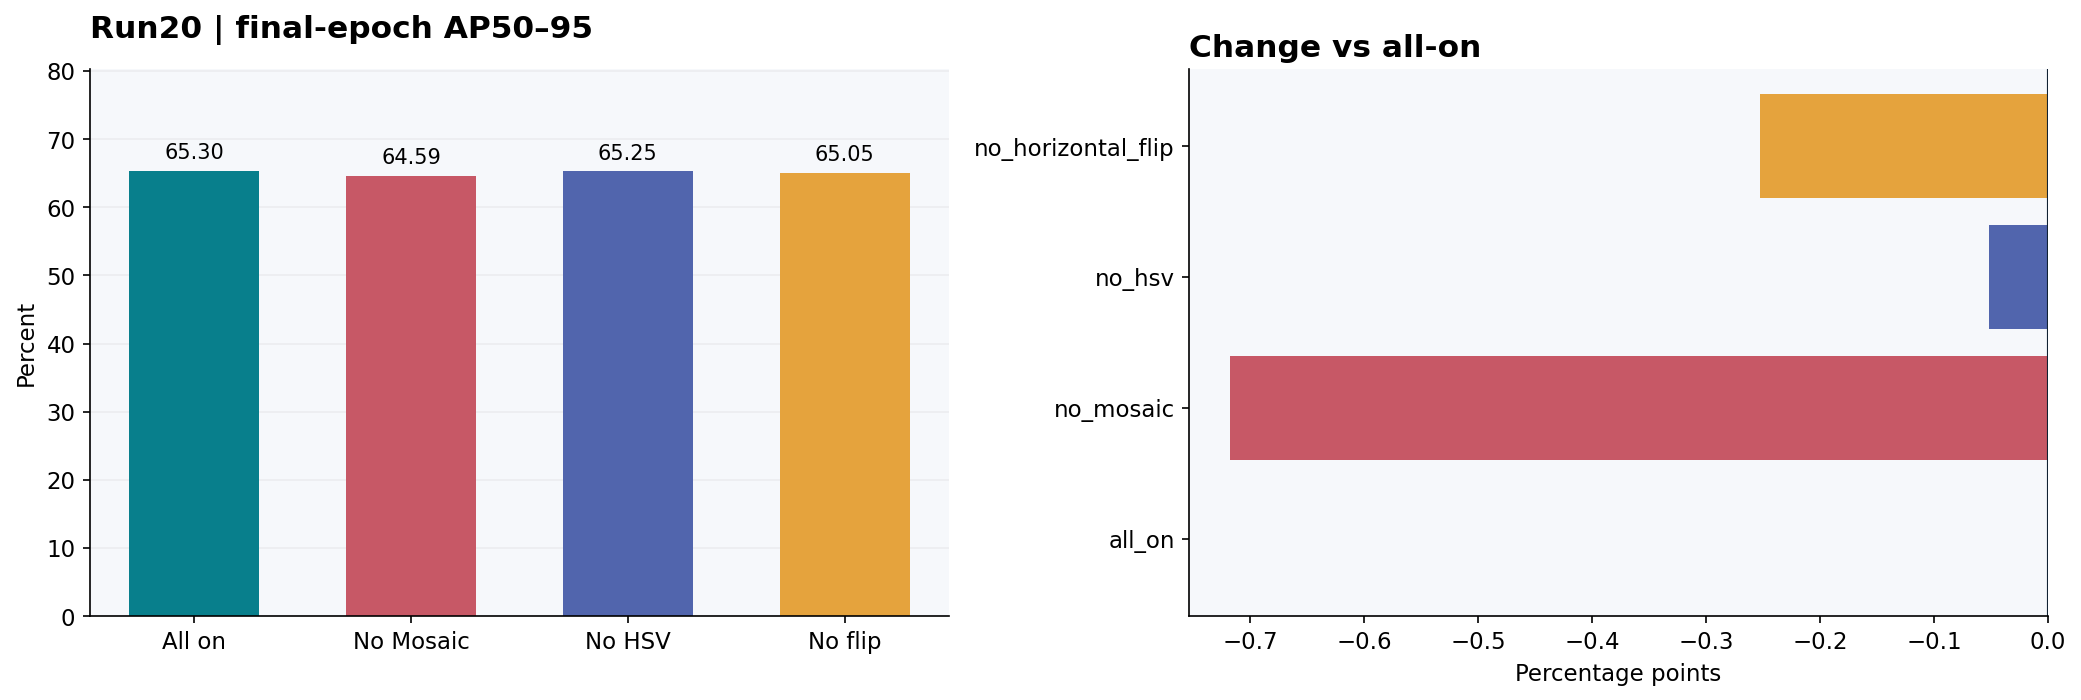

In [8]:
e=pd.DataFrame(DATA['e3']);display(e[['arm','epochs','training_seconds','mAP50','mAP50_95','delta_vs_all_on_pp']])
fig,axs=plt.subplots(1,2,figsize=(14,4.8));bars(axs[0],['All on','No Mosaic','No HSV','No flip'],e.mAP50_95*100,'Run20 | final-epoch AP50–95',color=[TEAL,RED,BLUE,AMBER]);axs[1].barh(e.arm,e.delta_vs_all_on_pp,color=[TEAL,RED,BLUE,AMBER]);axs[1].axvline(0,color='#123');axs[1].set_title('Change vs all-on',loc='left');axs[1].set_xlabel('Percentage points');plt.tight_layout()

**النتيجة:** all-on حقق 65.30%. إزالة Mosaic أنقصت 0.72 نقطة مئوية، وإزالة HSV أثرها صغير جدًا. تجربة قصيرة لا تثبت أن الزيادة مفيدة لكل مجال. لم نستبدل 17 بها.

## 8 | الدول وتحليل الأخطاء
21 قيم 8,281 صورة. الصين تطوير معاد الاستخدام؛ الولايات المتحدة مستبعدة من fine-tuning الفريق لكن تداخل المصدر المنشور مجهول. اليابان والهند والتشيك دول ممثلة في التدريب، ودعم الفئات غير متساوٍ.

country,images,ground_truth_boxes,supported_classes,mAP50_95,micro_precision,micro_recall,pothole_recall,evaluation_status
China_MotorBike,1977,4650,4,0.65790,0.89291,0.84452,0.96596,Evaluable on supported classes only
United_States,4804,11010,4,0.49727,0.82064,0.70854,0.31852,Evaluable on supported classes only
Japan,500,479,2,0.50528,0.84153,0.64301,N/A,Evaluable on supported classes only
India,500,42,2,0.40282,0.57500,0.54762,N/A,Evaluable on supported classes only
Czech,500,0,0,N/A,0.00000,N/A,N/A,No labeled damage boxes: AP/recall/F1 not evaluable


*Japan/India:2 supported classes. Czech:0 GT boxes -> AP/recall/F1 N/A, not zero.


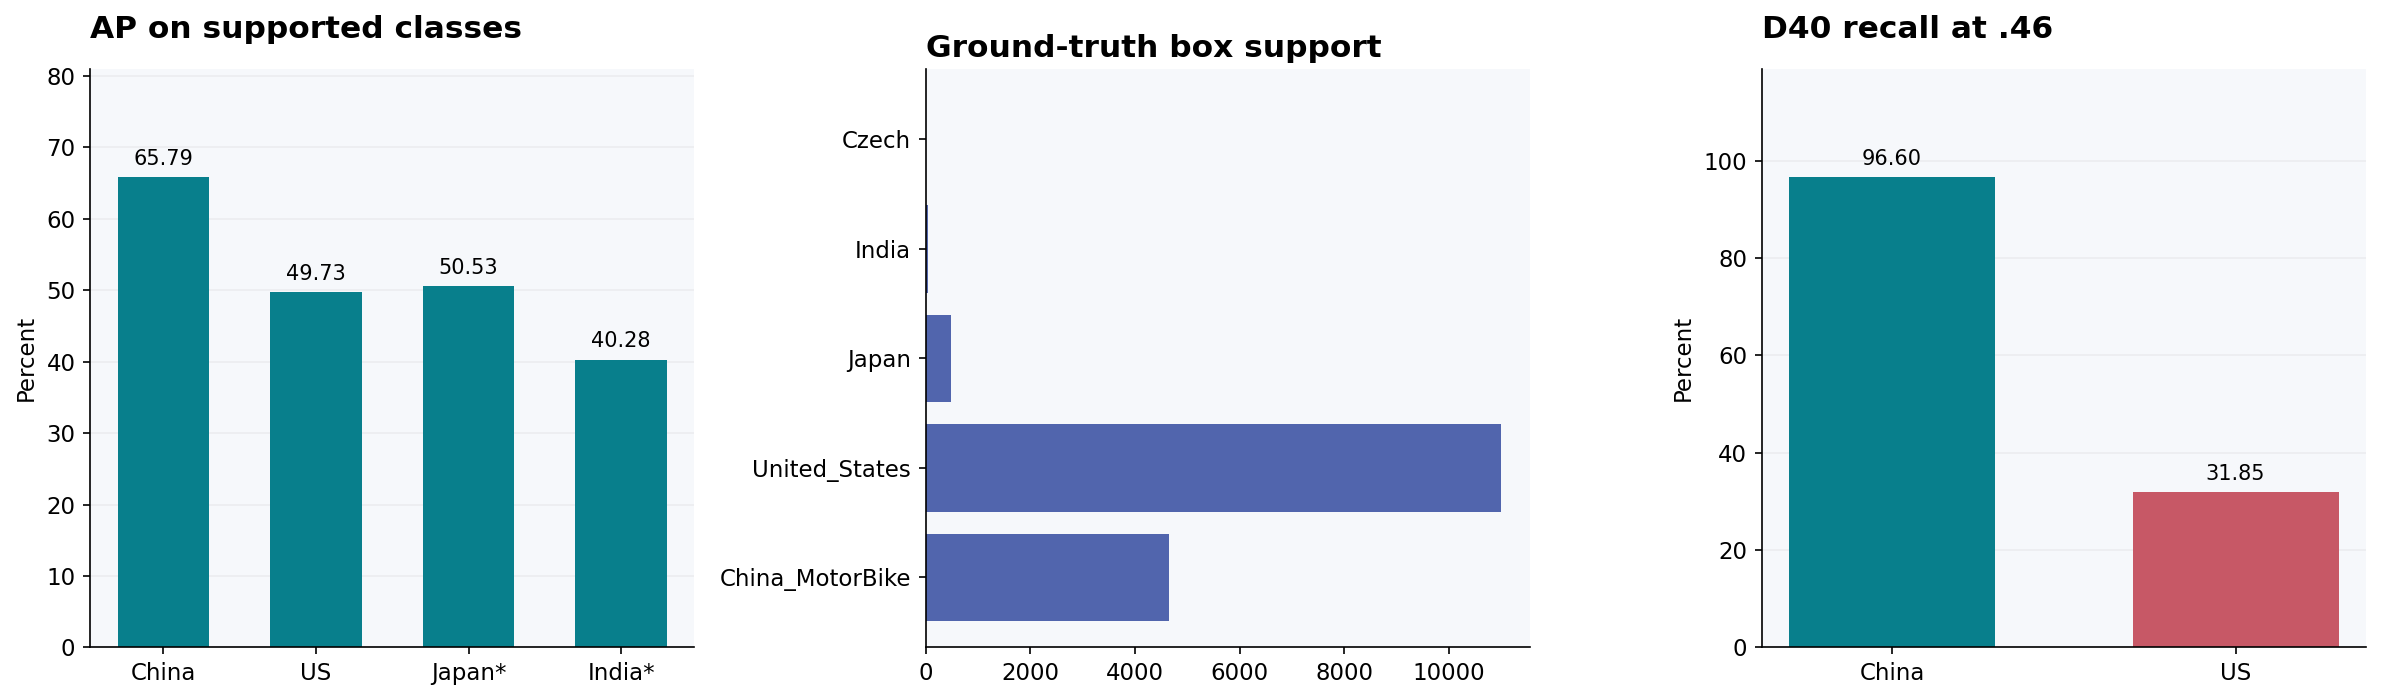

In [9]:
c=pd.DataFrame(DATA['countries']);display(c[['country','images','ground_truth_boxes','supported_classes','mAP50_95','micro_precision','micro_recall','pothole_recall','evaluation_status']])
fig,axs=plt.subplots(1,3,figsize=(16,4.8));v=c[c.mAP50_95.notna()]
bars(axs[0],['China','US','Japan*','India*'],v.mAP50_95*100,'AP on supported classes');axs[1].barh(c.country,c.ground_truth_boxes,color=BLUE);axs[1].set_title('Ground-truth box support',loc='left');bars(axs[2],['China','US'],[c.iloc[0].pothole_recall*100,c.iloc[1].pothole_recall*100],'D40 recall at .46',color=[TEAL,RED]);plt.tight_layout()
print('*Japan/India:2 supported classes. Czech:0 GT boxes -> AP/recall/F1 N/A, not zero.')

**النتيجة:** AP50–95 للصين 65.79% مقابل الولايات المتحدة 49.73%. استرجاع حفر أمريكا 43/135=31.85% فقط. لا يخفي المعدل العام هذا الضعف. التشيك بلا وسوم ضرر فلا نكتب AP=0 أو 100%. اليابان والهند محدودتا الدعم ومتأثرتان باختيار المكمل.

## 9 | البدائل الجديدة وAttention والدقة
23 قارن COCO YOLO11s مع C2PSA المدمجة مقابل YOLOv8s، على عينة v2 نفسها بدقة 640 وبذرة 42 وAdamW وميزانية 1.5 ساعة لكل ذراع. أكمل الأول 45 والثاني 47 epochs. التشغيل 14 لديه Attention مدمجة أصلًا؛ هذه مقارنة معماريتين وليست عزلًا سببيًا لأثر Attention.

model,AP50,AP5095,epochs,training_seconds
new11s,0.22733,0.08854,45,5479.23988
newv8s,0.19406,0.07068,47,5438.46156


model,size,AP5095
Run17,640,0.65790
Run17,960,0.46960
Run14,640,0.08732
Run14,960,0.04034
Run24new,640,0.64450
Run24new,960,0.49559
Run25new11m,640,0.10147
Run25new11m,960,0.07911


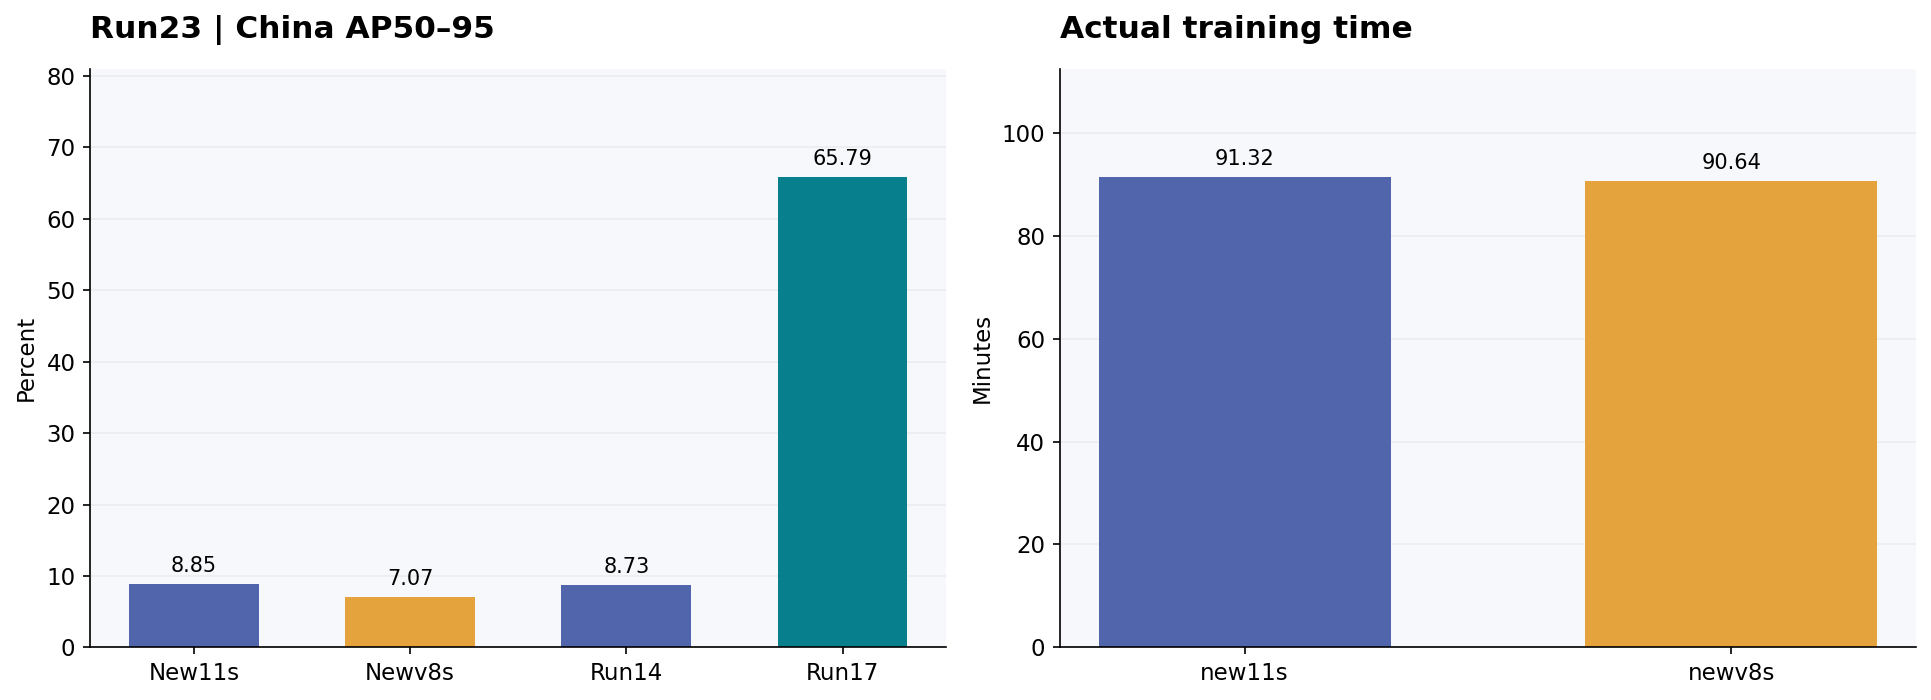

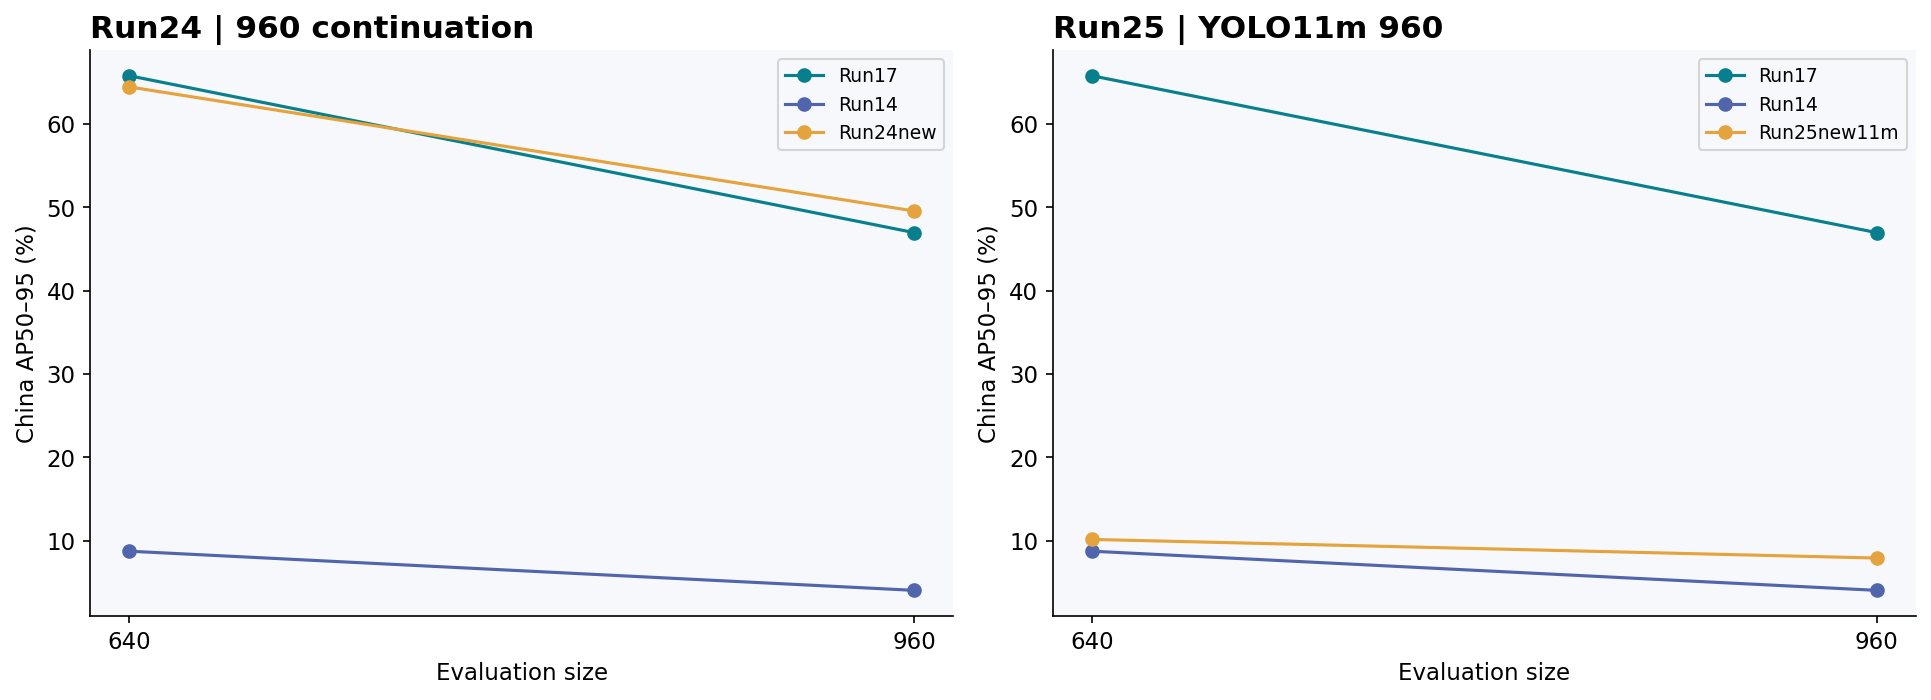

In [10]:
a=pd.DataFrame(DATA['new23']);display(a)
fig,axs=plt.subplots(1,2,figsize=(13,4.8));bars(axs[0],['New11s','Newv8s','Run14','Run17'],[8.85386,7.06751,8.7325,65.7899],'Run23 | China AP50–95',color=[BLUE,AMBER,BLUE,TEAL]);bars(axs[1],a.model,a.training_seconds/60,'Actual training time','Minutes',[BLUE,AMBER]);plt.tight_layout()
r=pd.DataFrame(DATA['resolution']);display(r)
fig,axs=plt.subplots(1,2,figsize=(13,4.8))
for ax,names,title in [(axs[0],['Run17','Run14','Run24new'],'Run24 | 960 continuation'),(axs[1],['Run17','Run14','Run25new11m'],'Run25 | YOLO11m 960')]:
    for name in names:
        q=r[r.model==name];ax.plot(q['size'],q.AP5095*100,marker='o',label=name)
    ax.set_title(title,loc='left');ax.set_xticks([640,960]);ax.set_xlabel('Evaluation size');ax.set_ylabel('China AP50–95 (%)');ax.legend(fontsize=9)
plt.tight_layout()

**القرار:** 23 لم يتفوق على 17. التشغيل 24 أكمل 10 epochs وتدريبًا نحو 29.1 دقيقة؛ الجديد عند 960 حقق 49.56% مقابل 65.79% للمرجع 17 عند 640. التشغيل 25 هو YOLO11m فعلًا رغم أسماء داخلية قديمة run24؛ أكمل 39 epochs وتدريبًا 6.015 ساعة، وحقق نحو 10.15% عند 640 و7.91% عند 960.
final_weights.pt في 24 و25 نسخة من 17 المرجعي وليست الأوزان الجديدة الفائزة. 26 فشل قبل التقييم بسبب RDD input مفقود؛ لا يوجد تحسن tiling أو WBF موثق. E2 لها أدلة جزئية، لكن مصفوفة Nano/Small ×640/960 المضبوطة كاملة على v2 لم تكتمل.

## 10 | المقارنة المحلية الصريحة
22 قارن 14 و17، ثم 27 قارن 23 على الصور نفسها: 190 صورة و333 مربعًا و56 صورة سليمة. المقاييس التشغيلية عند 0.46، أما AP فيعتمد ترتيب الدرجات. المجموعة كُشفت سابقًا؛ لا تعود holdout جديدًا بتغيير الموديل. لا تدريب ولا ضبط عتبة في هذا الملخص.

model,AP50,AP5095,P,R,F1,TP,FP,FN
Run17,0.26245,0.13149,0.50000,0.17417,0.25835,58,58,275
Run14,0.32097,0.13217,0.61194,0.12312,0.20500,41,26,292
Run23,0.24283,0.12250,0.71111,0.09610,0.16931,32,13,301


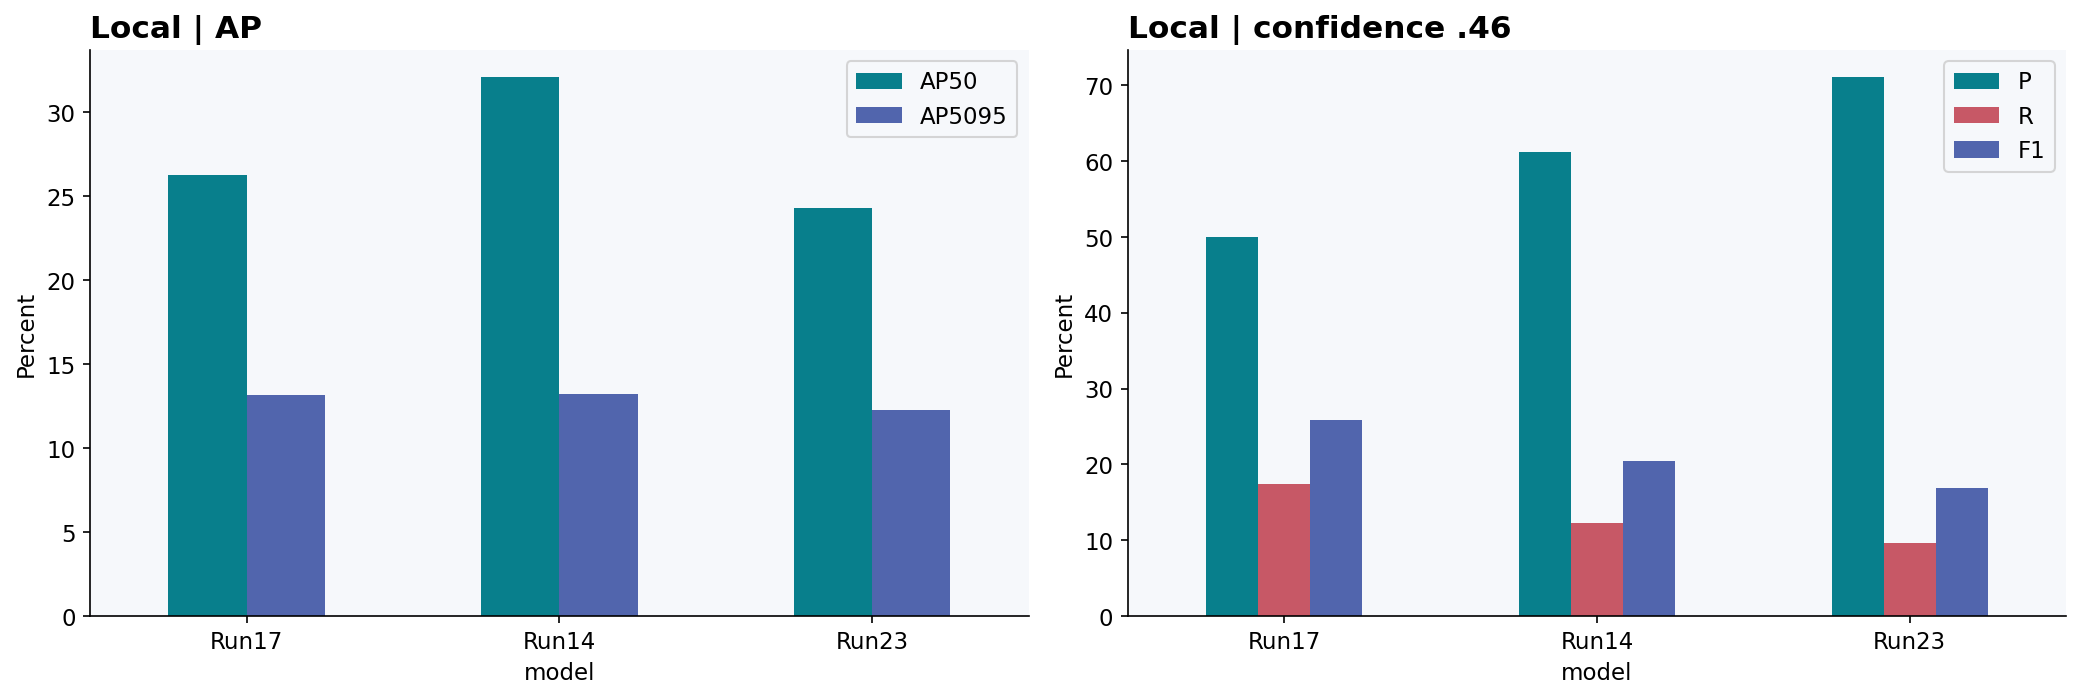

In [11]:
l=pd.DataFrame(DATA['local']);display(l)
fig,axs=plt.subplots(1,2,figsize=(14,4.8));l.set_index('model')[['AP50','AP5095']].mul(100).plot.bar(ax=axs[0],rot=0);axs[0].set_title('Local | AP',loc='left');l.set_index('model')[['P','R','F1']].mul(100).plot.bar(ax=axs[1],rot=0,color=[TEAL,RED,BLUE]);axs[1].set_title('Local | confidence .46',loc='left');axs[0].set_ylabel('Percent');axs[1].set_ylabel('Percent');plt.tight_layout()

**النتيجة:** 17 استرجع 58/333=17.42% مع Precision=50%. 14 استرجع 41=12.31% مع Precision=61.19%. 23 استرجع 32=9.61% مع Precision=71.11%. 17 يبقى اعتماد الفريق لكنه لم يثبت جاهزية ممتازة على الطرق المحلية. ارتفاع Precision مع قلة التوقعات لا يعني تعميمًا أفضل.

## 11 | ما أكثر الأخطاء؟
نقارن TP وFN للفئات. طول الشريط عدد وسوم الحقيقة، وليس عدد الصور. التشخيص يقترح فئات خطأ مشروطة بالإعدادات، وليس إثباتًا لخطأ الوسم.

class,TP,FP,FN,Recall
D00,19,22,136,0.12258
D10,4,15,87,0.04396
D20,17,9,21,0.44737
D40,18,12,31,0.36735


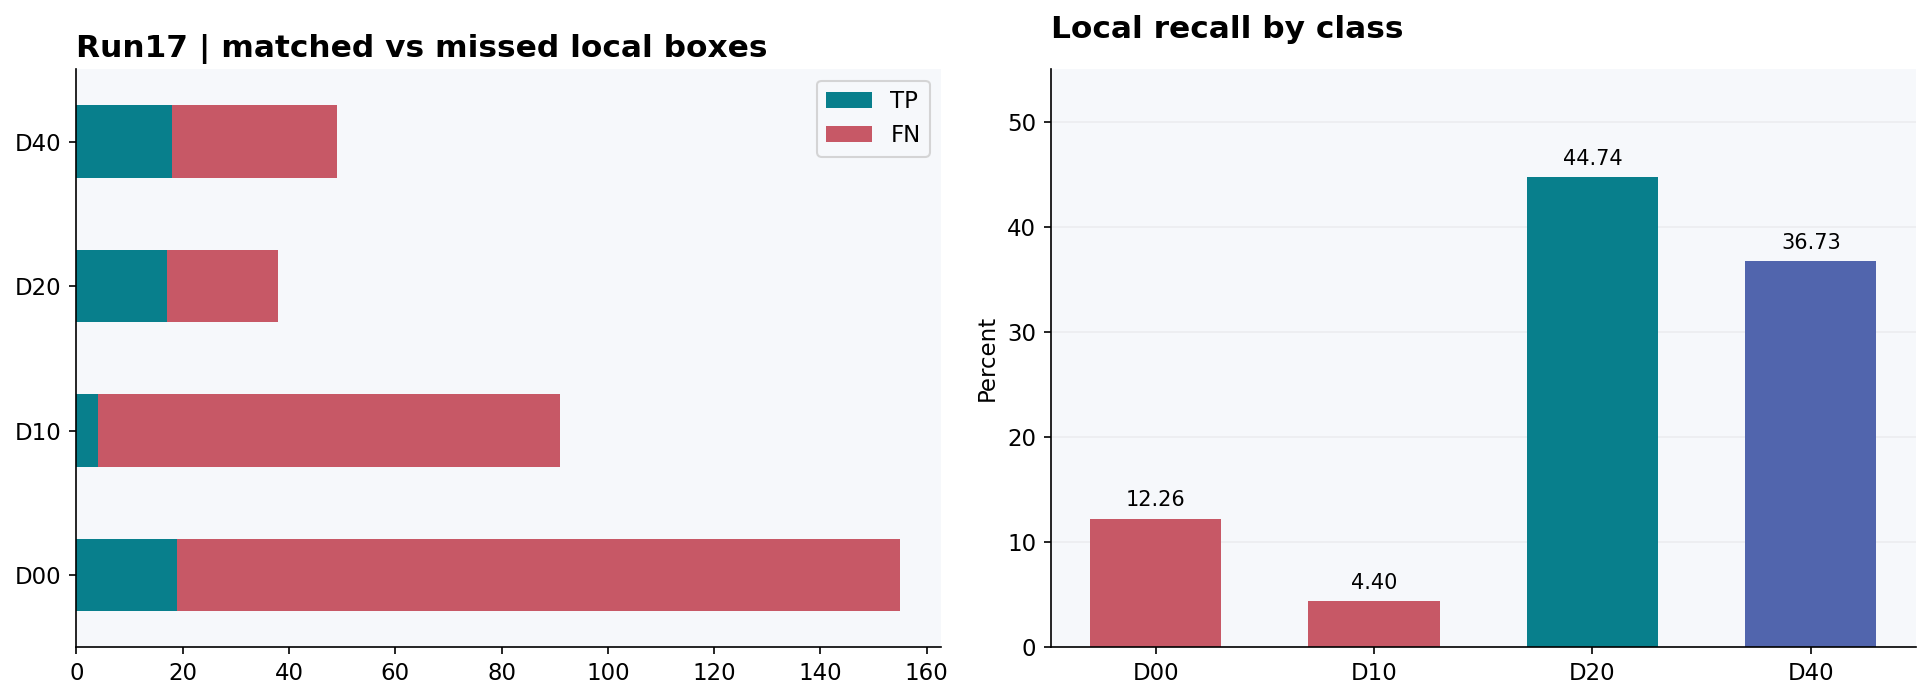

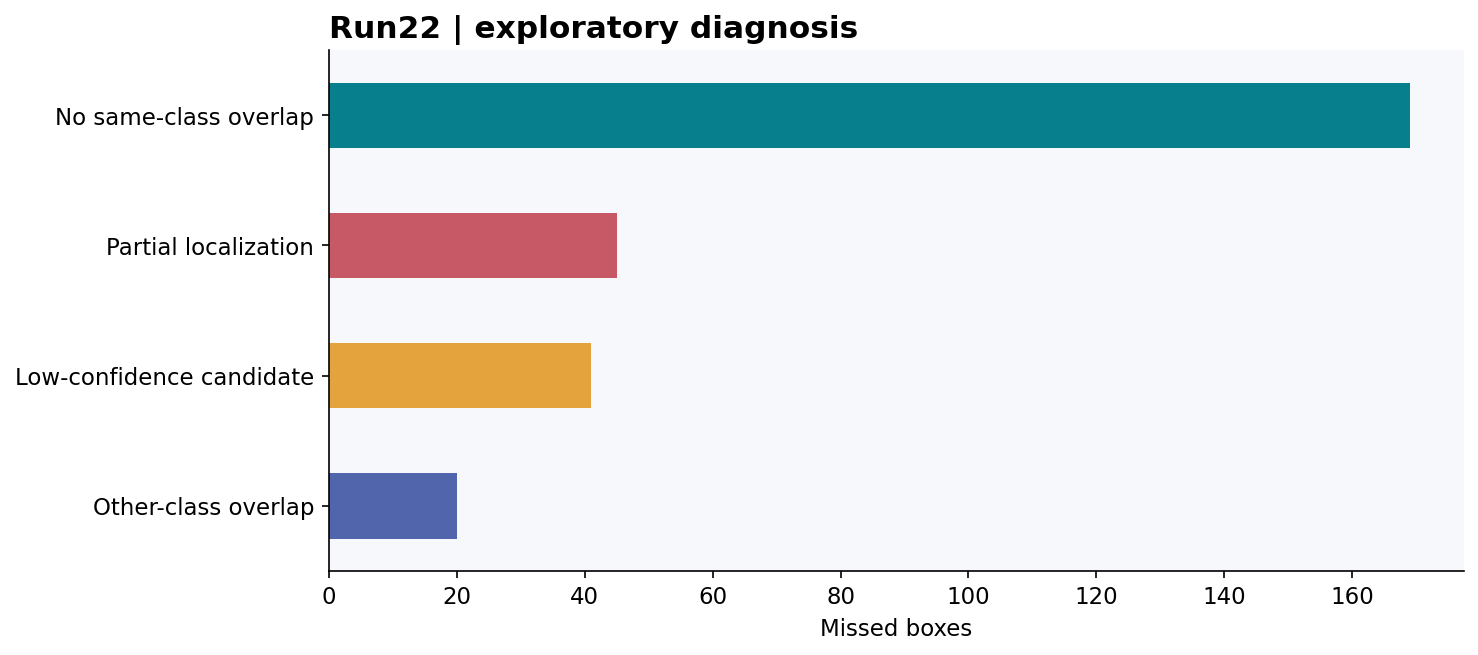

In [12]:
m=pd.DataFrame({'TP':[19,4,17,18],'FP':[22,15,9,12],'FN':[136,87,21,31]},index=['D00','D10','D20','D40']);m['Recall']=m.TP/(m.TP+m.FN)
fig,axs=plt.subplots(1,2,figsize=(13,4.8));m[['TP','FN']].plot.barh(stacked=True,ax=axs[0],color=[TEAL,RED]);axs[0].set_title('Run17 | matched vs missed local boxes',loc='left');bars(axs[1],m.index,m.Recall*100,'Local recall by class',color=[RED,RED,TEAL,BLUE]);plt.tight_layout();display(m.reset_index(names='class'))
fig,ax=plt.subplots(figsize=(10,4.5));pd.Series({'No same-class overlap':169,'Partial localization':45,'Low-confidence candidate':41,'Other-class overlap':20}).sort_values().plot.barh(ax=ax,color=[BLUE,AMBER,RED,TEAL]);ax.set_title('Run22 | exploratory diagnosis',loc='left');ax.set_xlabel('Missed boxes');plt.tight_layout()

**القراءة:** D00 وD10 يشكلان 223/275=81.1% من الفائت. التشخيص: 169 بلا تداخل من الفئة نفسها، و45 تحديد جزئي، و41 ثقة منخفضة، و20 فئة أخرى. الشقوق الرفيعة والطويلة صعبة، لكن لا ننسب كل خطأ للوسم دون مراجعة.

## 12 | خفض العتبة ليس حلًا مجانيًا
27 اختبر 0.001 المختارة من الصين مسبقًا و0.46 للمقارنة. لم نبحث عن أفضل عتبة على المحلي. نقيس الإنذارات على الصور السليمة أيضًا.

confidence,P,R,F1,TP,FP,FN,healthy_alarms,healthy_false_boxes
0.00100,0.00876,0.44444,0.01719,148,16740,185,56,2015
0.46000,0.71111,0.09610,0.16931,32,13,301,1,1


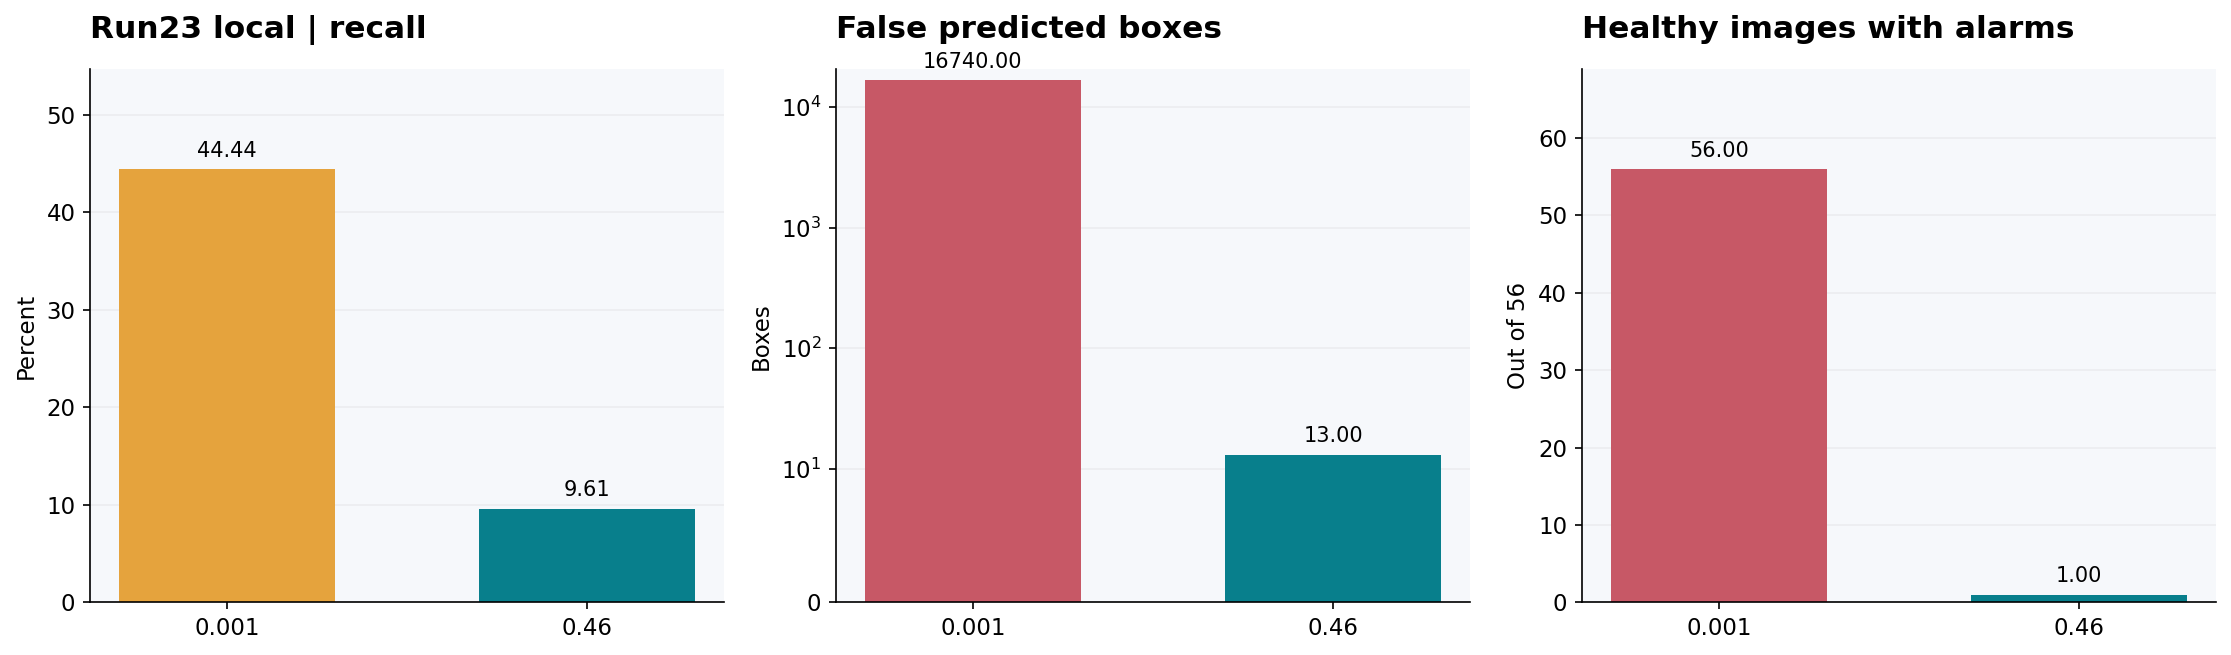

In [13]:
q=pd.DataFrame(DATA['local27_thresholds']);display(q)
fig,axs=plt.subplots(1,3,figsize=(15,4.5));labels=q.confidence.astype(str);bars(axs[0],labels,q.R*100,'Run23 local | recall',color=[AMBER,TEAL]);bars(axs[1],labels,q.FP,'False predicted boxes','Boxes',[RED,TEAL]);axs[1].set_yscale('symlog',linthresh=10);bars(axs[2],labels,q.healthy_alarms,'Healthy images with alarms','Out of 56',[RED,TEAL]);plt.tight_layout()

**النتيجة:** 0.001 رفعت الاسترجاع إلى 44.44% لكنها أنتجت 16,740 FP وأنذرت على كل الصور السليمة الـ56. عند 0.46 أنذر على صورة سليمة واحدة، لكن الفائت كبير. لا نعتمد خفض الثقة كحل جذري.

## 13 | الوقت: ما الموثق وما المجهول؟
مدد كاغل تشمل التجهيز والتقييم، وبعض القديمة مقرب. Quick Version ليست مدة تدريب؛ وقت 22 الفعلي مجهول و11 ثانية كانت وقت الحفظ. لا نحول المجهول إلى صفر. مجموع الأحداث أدناه ليس كل GPU billing ولا ساعات العمل البشري.

run,event,seconds,time_basis,minutes
3,pilot,812.00000,Kaggle Save & Run All,13.53333
4,controlled pilot,12300.00000,rounded Kaggle elapsed; failed/OOM,205.00000
5,evaluation recovery,720.00000,rounded; no retraining,12.00000
5,v1 YOLO v2,5520.00000,rounded Kaggle elapsed,92.00000
5,v4 YOLO v2,11520.00000,rounded Kaggle elapsed,192.00000
6,quality/resolution,26340.00000,rounded Kaggle elapsed,439.00000
7,diagnosis/evaluation,N/A,unknown: Quick export does not measure execution,N/A
8,diagnosis/evaluation,N/A,unknown: Quick export does not measure execution,N/A
9,diagnosis/evaluation,N/A,unknown: Quick export does not measure execution,N/A
10,diagnosis/evaluation,N/A,unknown: Quick export does not measure execution,N/A


Documented elapsed-time subtotal: 31.61 h
Excludes unknown/Quick durations. Includes failed partial Run04 work.
Run23 training only: 3.0326948430683336 h
Run20 training arms only: 60.46163610275 min


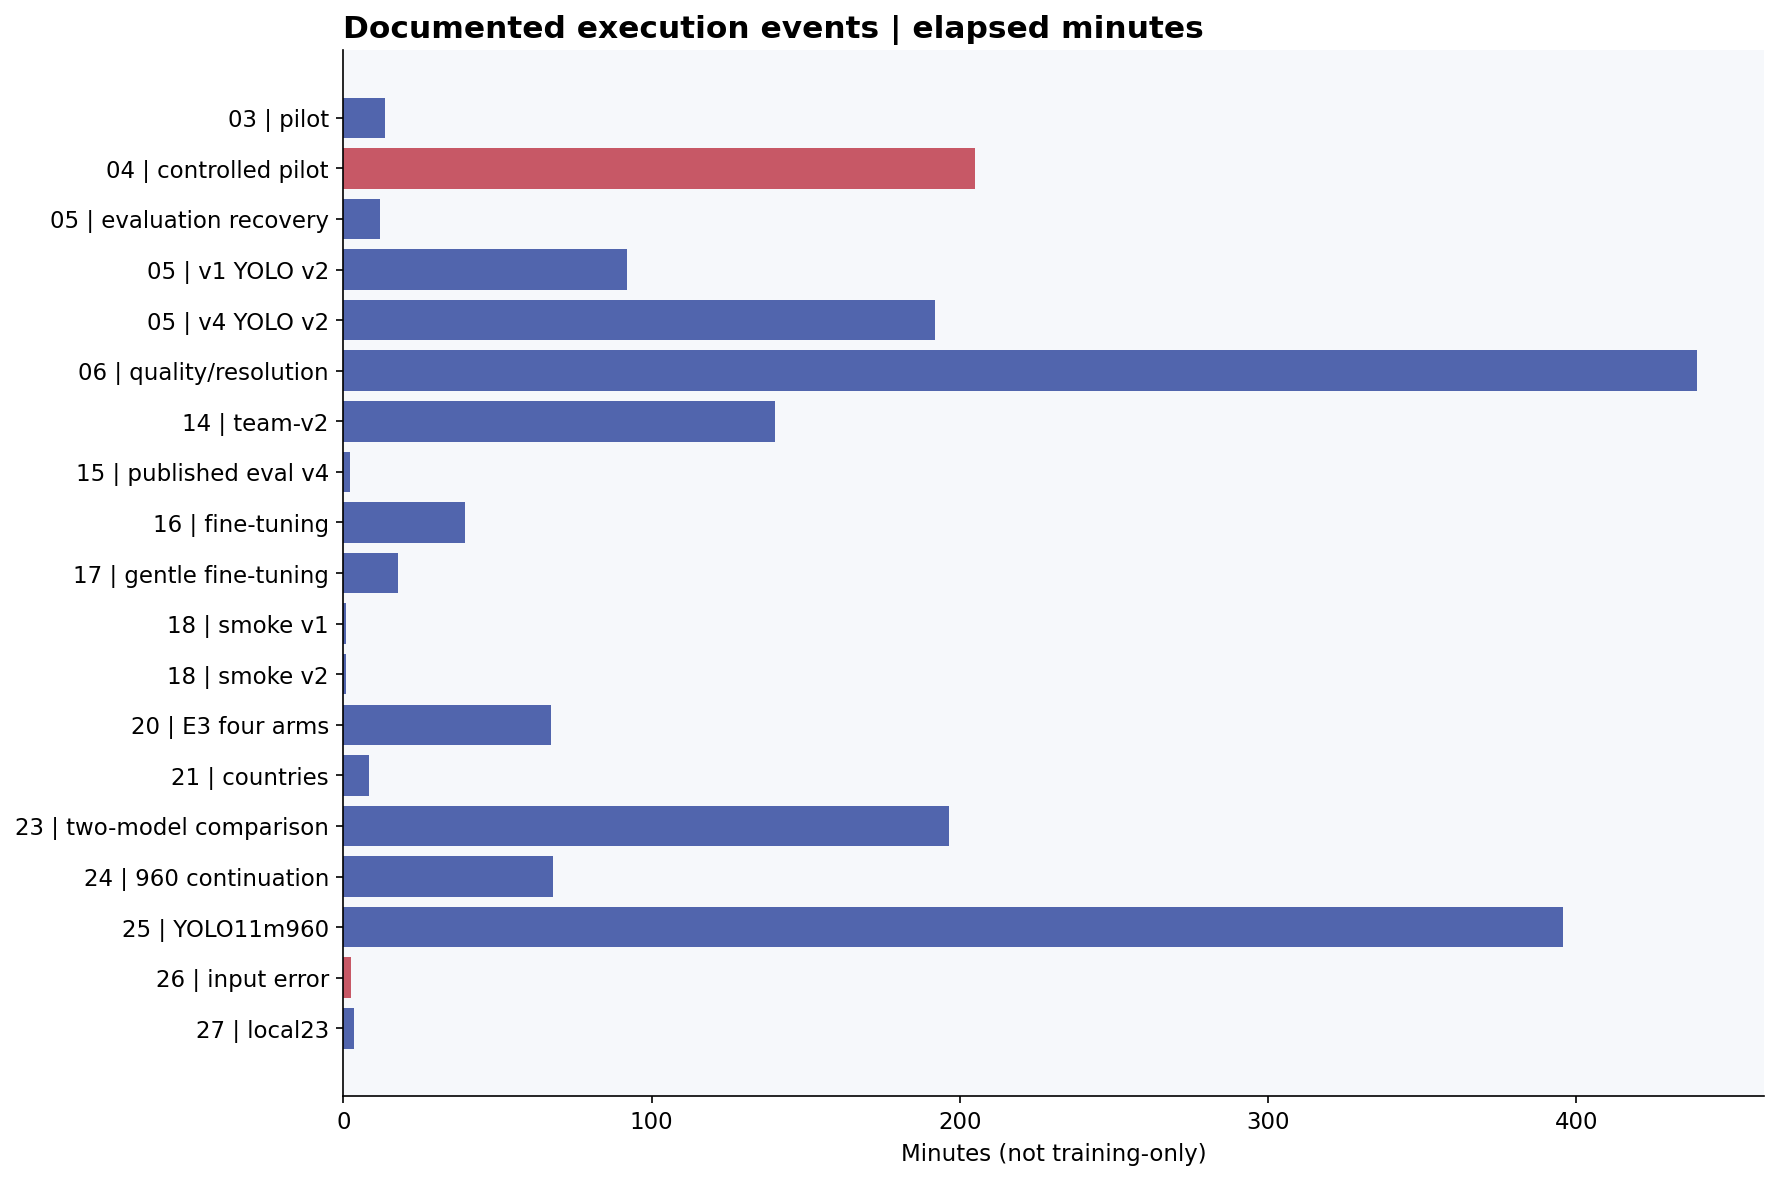

In [14]:
rt=pd.DataFrame(DATA['times']);rt['minutes']=rt.seconds/60;display(rt);known=rt[rt.seconds.notna()]
fig,ax=plt.subplots(figsize=(12,8));ax.barh([f'{int(r.run):02} | {r.event}' for _,r in known.iterrows()],known.minutes,color=[RED if 'failed' in b else BLUE for b in known.time_basis]);ax.invert_yaxis();ax.set_title('Documented execution events | elapsed minutes',loc='left');ax.set_xlabel('Minutes (not training-only)');plt.tight_layout()
print(f'Documented elapsed-time subtotal: {known.seconds.sum()/3600:.2f} h')
print('Excludes unknown/Quick durations. Includes failed partial Run04 work.')
print('Run23 training only:',sum(x['training_seconds'] for x in DATA['new23'])/3600,'h')
print('Run20 training arms only:',sum(x['training_seconds'] for x in DATA['e3'])/60,'min')

**القراءة:** زيادة الوقت والحجم ليست ضمانًا للتحسن. 25 أخذ نحو 6 ساعات و36 دقيقة مع التجهيز والتقييم دون تفوق. المدد الناقصة معلنة بدل إعطاء تقديرات غير موثقة.

## 14 | المنجز والمتبقي ضمن نطاق الكاشف
نميز المنجز عن الجزئي والفاشل. هذه قائمة كاشف YOLO فقط وليست شهادة بكل checklist الفريق. E1 وE5 والتطبيق لها أدلتها المنفصلة، وقد تكون عند الزميلات. لم تُراجع هنا بوصفها تجارب الكاشف.

Task,State,Evidence / remaining
D classes / YOLO pipeline,Done,14–18
v2 training / fine-tuning,Done,14/16/17
D-code helper smoke,Done,"18,15 RDD images"
Frozen threshold + confusion/F1 outputs,Done,17/19
E3 augmentation,Done; short/single-seed,20
Country/error review,Done with support caveats,21
Local diagnostic comparison,Done; not fresh holdout,22/27
New architecture/size/resolution alternatives,Done; no isolated attention claim,23–25
Full controlled E2 grid,Partial,Nano/Small ×640/960 not complete
USA tiling,Failed,26 missing input


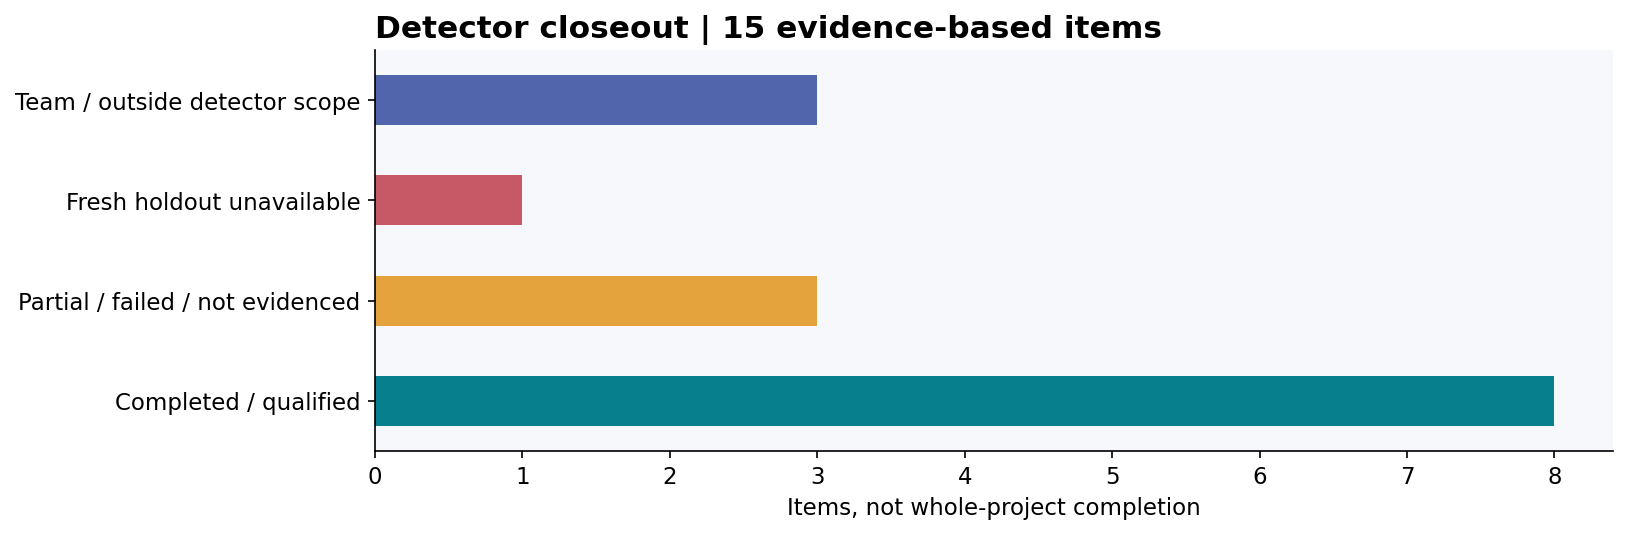

In [15]:
status=pd.DataFrame([
 ['D classes / YOLO pipeline','Done','14–18'],['v2 training / fine-tuning','Done','14/16/17'],['D-code helper smoke','Done','18,15 RDD images'],['Frozen threshold + confusion/F1 outputs','Done','17/19'],['E3 augmentation','Done; short/single-seed','20'],['Country/error review','Done with support caveats','21'],['Local diagnostic comparison','Done; not fresh holdout','22/27'],['New architecture/size/resolution alternatives','Done; no isolated attention claim','23–25'],['Full controlled E2 grid','Partial','Nano/Small ×640/960 not complete'],['USA tiling','Failed','26 missing input'],['WBF improvement','Not evidenced','No completed saved result'],['Fresh independent local final test','Unavailable here','190 already inspected/reused'],['E1 comparison','Team coordination','Need matched baseline metrics'],['E5 duplicate comparison','Outside detector scope','See duplicate owner evidence'],['Full app latency/privacy/end-to-end','Outside detector test evidence','See application/integration owner']],columns=['Task','State','Evidence / remaining']);display(status)
fig,ax=plt.subplots(figsize=(11,3.7));pd.Series({'Completed / qualified':8,'Partial / failed / not evidenced':3,'Fresh holdout unavailable':1,'Team / outside detector scope':3}).plot.barh(ax=ax,color=[TEAL,AMBER,RED,BLUE]);ax.set_title('Detector closeout | 15 evidence-based items',loc='left');ax.set_xlabel('Items, not whole-project completion');plt.tight_layout()

## 15 | الاعتماد والمساهمة والتسليم
المعتمد run17_best_finetuned.pt. البصمة تمنع خلطه بالأصل selected_candidate.pt أو نسخ final_weights المرجعية. الأوزان 14 و16 و17 في Release v2-yolo الموجود. هذه النوتبوك لا تستبدل وزنًا.
المساهمة: مسار تدريب موثق وتوحيد الفئات والعينة والتعديل اللطيف والعتبة والدالة والتشخيص والزيادة والتقييم والتوثيق. ننسب الأوزان المبدئية لناشرها SreekarAditya/yolo-rdd2022-benchmark وبيانات RDD2022 لأصحابها، ونحافظ على شروط Ultralytics.

In [16]:
keys=['adopted_run','checkpoint','sha256','confidence','imgsz','nms_iou','max_det','local_independent'];print(json.dumps({k:DATA[k] for k in keys},indent=2))
assert DATA['adopted_run']==17 and DATA['confidence']==.46
assert all(x['TP']+x['FN']==333 for x in DATA['local'])
assert sum([155,91,38,49])==333
print('Consistency checks passed. No model execution, retraining or local threshold search.')

{
  "adopted_run": 17,
  "checkpoint": "run17_best_finetuned.pt",
  "sha256": "25b412ff18c05e2607f4bc61b872f39826e8d53ffdc7647654c1f419e355d15f",
  "confidence": 0.46,
  "imgsz": 640,
  "nms_iou": 0.7,
  "max_det": 300,
  "local_independent": false
}
Consistency checks passed. No model execution, retraining or local threshold search.


## 16 | مصادر الأرقام وإعادة التشغيل
- results/run14 إلى run21: JSON ومخرجات التجارب. country_error_reviewed.json مرجع التصحيحات.
- notebooks/yolo/22 إلى 27: المصادر المحفوظة في كاغل؛ حُذفت مخرجات صور المحلي الشخصية من تصدير 22 فقط.
- results/run28/summary_data.json: اللقطة المضمنة في النوتبوك.
- historical_output_tables.json: 81 جدولًا تاريخيًا مع اسم المصدر ونسخته وموضع الجدول.
- archive_version_inventory.csv: فهرس 30 نسخة بالأوقات والفشل والإلغاء.
- run22_table_*.csv إلى run27_table_*.csv: الجداول المنقولة من المخرجات المحفوظة.
تشغيل النوتبوك: Python 3 مع numpy وpandas وmatplotlib ثم Run All، دون إنترنت أو GPU. الرسوم مسجلة من تنفيذ الأكواد على المخرجات المحفوظة وليست تقييمًا جديدًا للنماذج. قيم الرسوم المبكرة مقربة؛ النسخ الأصلية والجداول هي المرجع الأدق.
حدود الاستنتاج: تداخل المصدر المنشور مجهول، والصين تطوير معاد استخدامه، والمحلي مكشوف وموسوم بمساعدة AI ومراجعة الفريق وليس مدققًا استقلاليًا. تحقق الوسوم يشمل الأشياء الفائتة والخاطئة وامتداد المربعات؛ لا يكفي قبول اقتراح المساعد آليًا. لا يوجد تكرار بذور حديث أو دليل سببي خاص بـAttention.